# 接单时的外卖晚到风险识别

本研究在骑手接单时（`grab_time`）预测订单是否晚于平台记录的预计送达时间（ETA），比较随机排序、距离规则、Logistic Regression 和 XGBoost 在有限监控容量下的识别表现。主标签 `y_0` 对应任何超过 ETA 的送达，`y_8` 用于检查较明显延迟下的敏感性。结果属于历史数据上的预测评估，未测量干预后的晚到减少量。

所有日期、小时和数据划分均使用北京时间（`Asia/Shanghai`）。模型输入限于按业务定义在接单时已产生的字段；实际送达、取餐等后续事件只用于标签或事后分析。记录 ETA 的历史版本未确认，ETA 提前量应理解为回溯指标。

## 运行说明

在项目根目录安装 `requirements.txt` 中记录的依赖，然后从 `notebooks/` 目录启动 Jupyter，选择相同 Python 环境的内核并从头依次运行。当前相对路径要求内核工作目录为 `notebooks/`。

```bash
python -m pip install -r requirements.txt
cd notebooks
python -m jupyterlab food_delivery_analysis.ipynb
```

必需输入为 `../data/Meituan-INFORMS-TSL-Research-Challenge/all_waybill_info_meituan_0322.csv` 和 `../data/data_dictionary.csv`。运行环境记录为 Python 3.13.15、pandas 3.1.0、NumPy 2.5.4、scikit-learn 1.9.1、XGBoost 3.4.1、Matplotlib 3.11.2；这些版本取自本地 `lab` 环境。SHAP 贡献由 XGBoost 原生接口计算，无需另装 `shap`。

最后一节自动创建 `../results/`，并写入或覆盖 `dashboard_order_scores.csv` 和 `dashboard_metrics.csv`。文中数值对应随 notebook 保留的输出；更换数据或运行环境后，应以重新运行的结果更新说明。数据获取与使用条件见项目随附的 `License.txt`。


In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import ParameterGrid
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    brier_score_loss
)

from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

RANDOM_SEED = 42


In [2]:
# 相对路径以 notebooks/ 为工作目录。
CSV_PATH = Path("../data/Meituan-INFORMS-TSL-Research-Challenge/all_waybill_info_meituan_0322.csv")
DATA_DICT_PATH = Path("../data/data_dictionary.csv")


## 1. 数据准备

分析使用美团运单主表及项目数据字典。原始数据包含同一订单的不同派单记录；筛选已接单且关键时间有效的记录后，检查订单标识是否唯一，以订单为分析单位。


In [3]:
df_raw = pd.read_csv(CSV_PATH)

print("数据规模：", df_raw.shape)
display(df_raw.head())
display(df_raw.dtypes)


数据规模： (654343, 24)


,Unnamed: 0,dt,order_id,waybill_id,courier_id,da_id,is_courier_grabbed,is_weekend,estimate_arrived_time,is_prebook,poi_id,sender_lng,sender_lat,recipient_lng,recipient_lat,grab_lng,grab_lat,dispatch_time,grab_time,fetch_time,arrive_time,estimate_meal_prepare_time,order_push_time,platform_order_time
0,0,20221017,0,0,0,0,0,1,1665937978,0,0,174579111,45862631,174600135,45852786,0,0,1665936258,0,0,0,1665936779,1665936000,1665935996
1,1,20221017,1,1,1,1,1,1,1665937864,0,1,174529930,45905850,174522983,45898250,174530062,45906005,1665936734,1665936737,1665937344,1665937798,1665936845,1665936006,1665935995
2,2,20221017,2,2,2,2,1,0,1665939504,0,2,174532407,45861460,174547033,45891243,174548244,45870923,1665937484,1665937501,1665938346,1665939384,1665938007,1665937107,1665937097
3,3,20221017,3,3,3,0,1,0,1665939432,0,3,174559718,45868015,174595327,45886787,174560199,45867948,1665937394,1665937397,1665937830,1665939822,1665937634,1665937369,1665937028
4,4,20221017,4,4,4,0,1,0,1665938894,0,3,174559718,45868015,174534558,45867411,174554896,45865167,1665937394,1665937413,1665937710,1665938262,1665937694,1665937373,1665937092


Unnamed: 0                    int64
dt                            int64
order_id                      int64
waybill_id                    int64
courier_id                    int64
da_id                         int64
is_courier_grabbed            int64
is_weekend                    int64
estimate_arrived_time         int64
is_prebook                    int64
poi_id                        int64
sender_lng                    int64
sender_lat                    int64
recipient_lng                 int64
recipient_lat                 int64
grab_lng                      int64
grab_lat                      int64
dispatch_time                 int64
grab_time                     int64
fetch_time                    int64
arrive_time                   int64
estimate_meal_prepare_time    int64
order_push_time               int64
platform_order_time           int64
dtype: object

In [4]:
misssing_table = pd.DataFrame({
    'missing_count': df_raw.isna().sum(),
    'missing_rate': df_raw.isna().mean()
})

display(misssing_table)


,missing_count,missing_rate
Unnamed: 0,0,0.0
dt,0,0.0
order_id,0,0.0
waybill_id,0,0.0
courier_id,0,0.0
da_id,0,0.0
is_courier_grabbed,0,0.0
is_weekend,0,0.0
estimate_arrived_time,0,0.0
is_prebook,0,0.0


In [5]:
data_dict = pd.read_csv(DATA_DICT_PATH)

display(data_dict)


,原始字段,中文含义与表示,本项目用途
0,Unnamed: 0,导出行索引，无业务含义,删除，不当作特征
1,dt,记录日期码，形如 YYYYMMDD；不直接等同于下单日期,描述与日期核对；正式切分使用接单日期
2,order_id,匿名订单标识,关联同一订单的多次运单，订单级去重
3,waybill_id,匿名运单标识,区分派单记录；不直接建模
4,courier_id,该运单被派给的匿名骑手标识,骑手分组、历史特征；不按数值大小解释
5,da_id,商圈或运营区域标识,分组分析及类别特征；不是严格互斥的纯地理分区
6,is_courier_grabbed,是否接受运单，1 接受、0 未接受,筛选已接单样本；筛选后不作为特征
7,is_weekend,创建日是否周末，0/1,描述性分组；原始标记与接单日周末需区分，首轮模型暂不使用
8,estimate_arrived_time,平台记录的承诺/预计送达时刻，Unix 秒,生成标签和回溯提前量；历史版本未确认，不作核心输入
9,is_prebook,是否预约订单，0/1,描述、分层和模型特征


## 2. 数据清洗

原始数据共 654,343 条运单记录，其中 568,546 条已接单。排除 1 条接单、送达或 ETA 时间无效的记录后，保留 568,545 笔订单，订单 ID 无重复。其余非正时间戳转为缺失，负阶段耗时不参与统计；坐标按字段尺度转换并检查取值范围。


In [6]:
# 保留已接单且接单、送达、ETA 时间有效的记录，并核对订单唯一性。
accepted_mask = df_raw["is_courier_grabbed"].eq(1)

required_time_cols = [
    "grab_time",
    "arrive_time",
    "estimate_arrived_time"
]

valid_time_mask = (
    df_raw[required_time_cols]
    .gt(0)
    .all(axis=1)
)

df_clean = (
    df_raw.loc[accepted_mask & valid_time_mask]
    .drop(columns=["Unnamed: 0"])
    .copy()
)

cleaning_summary = pd.Series({
    "原始运单数": len(df_raw),
    "已接单运单数": accepted_mask.sum(),
    "已接单但关键时间无效": (
        accepted_mask & ~valid_time_mask
    ).sum(),
    "保留的完成订单数": len(df_clean),
    "重复订单记录数": df_clean["order_id"].duplicated().sum()
}, name="数量")

display(cleaning_summary.to_frame())


,数量
原始运单数,654343
已接单运单数,568546
已接单但关键时间无效,1
保留的完成订单数,568545
重复订单记录数,0


In [7]:
# 非正时间戳视为缺失；其余字段保持原值。
time_cols = [
    "platform_order_time",
    "order_push_time",
    "dispatch_time",
    "grab_time",
    "fetch_time",
    "arrive_time",
    "estimate_arrived_time",
    "estimate_meal_prepare_time"
]

df_clean[time_cols] = (
    df_clean[time_cols]
    .mask(df_clean[time_cols].le(0))
)

time_missing = df_clean[time_cols].isna().sum()

display(time_missing[time_missing > 0].to_frame("缺失数量"))


,缺失数量
dispatch_time,1
estimate_meal_prepare_time,9874


In [8]:
# Unix 秒先按 UTC 解析，再转换为北京时间。
for col in time_cols:
    df_clean[f"{col}_dt"] = (
        pd.to_datetime(
            df_clean[col],
            unit="s",
            utc=True,
            errors="coerce"
        )
        .dt.tz_convert("Asia/Shanghai")
    )

display(
    df_clean[[
        "order_id",
        "platform_order_time_dt",
        "order_push_time_dt",
        "grab_time_dt",
        "arrive_time_dt"
    ]].head()
)


,order_id,platform_order_time_dt,order_push_time_dt,grab_time_dt,arrive_time_dt
1,1,2022-10-16 23:59:55+08:00,2022-10-17 00:00:06+08:00,2022-10-17 00:12:17+08:00,2022-10-17 00:29:58+08:00
2,2,2022-10-17 00:18:17+08:00,2022-10-17 00:18:27+08:00,2022-10-17 00:25:01+08:00,2022-10-17 00:56:24+08:00
3,3,2022-10-17 00:17:08+08:00,2022-10-17 00:22:49+08:00,2022-10-17 00:23:17+08:00,2022-10-17 01:03:42+08:00
4,4,2022-10-17 00:18:12+08:00,2022-10-17 00:22:53+08:00,2022-10-17 00:23:33+08:00,2022-10-17 00:37:42+08:00
5,5,2022-10-17 00:39:59+08:00,2022-10-17 00:40:03+08:00,2022-10-17 00:45:41+08:00,2022-10-17 01:14:56+08:00


In [9]:
# 核查业务事件的先后顺序；此处仅统计异常，不删除记录。
time_order_issues = pd.Series({
    "进入调度早于下单": (
        df_clean["order_push_time"]
        < df_clean["platform_order_time"]
    ).sum(),

    "派单早于进入调度": (
        df_clean["dispatch_time"]
        < df_clean["order_push_time"]
    ).sum(),

    "接单早于派单": (
        df_clean["grab_time"]
        < df_clean["dispatch_time"]
    ).sum(),

    "取餐早于接单": (
        df_clean["fetch_time"]
        < df_clean["grab_time"]
    ).sum(),

    "送达早于取餐": (
        df_clean["arrive_time"]
        < df_clean["fetch_time"]
    ).sum()
}, name="异常数量")

display(time_order_issues.to_frame())


,异常数量
进入调度早于下单,0
派单早于进入调度,0
接单早于派单,0
取餐早于接单,0
送达早于取餐,0


In [10]:
# 坐标按百万分之一度转换；无效坐标置为缺失，原始字段保留。
for prefix in ["sender", "recipient", "grab"]:
    lng = df_clean[f"{prefix}_lng"] / 1_000_000
    lat = df_clean[f"{prefix}_lat"] / 1_000_000

    valid_location = (
        lng.between(-180, 180)
        & lat.between(-90, 90)
        & lng.ne(0)
        & lat.ne(0)
    )

    df_clean[f"{prefix}_lng_deg"] = lng.where(valid_location)
    df_clean[f"{prefix}_lat_deg"] = lat.where(valid_location)

coordinate_cols = [
    "sender_lng_deg", "sender_lat_deg",
    "recipient_lng_deg", "recipient_lat_deg",
    "grab_lng_deg", "grab_lat_deg"
]

display(df_clean[coordinate_cols].head())
display(
    df_clean[coordinate_cols]
    .isna()
    .sum()
    .to_frame("坐标缺失数量")
)


,sender_lng_deg,sender_lat_deg,recipient_lng_deg,recipient_lat_deg,grab_lng_deg,grab_lat_deg
1,174.529930,45.905850,174.522983,45.898250,174.530062,45.906005
2,174.532407,45.861460,174.547033,45.891243,174.548244,45.870923
3,174.559718,45.868015,174.595327,45.886787,174.560199,45.867948
4,174.559718,45.868015,174.534558,45.867411,174.554896,45.865167
5,174.542688,45.920329,174.530185,45.921310,174.526338,45.912309


,坐标缺失数量
sender_lng_deg,0
sender_lat_deg,0
recipient_lng_deg,0
recipient_lat_deg,0
grab_lng_deg,0
grab_lat_deg,0


### 标签定义

`delay_sec = arrive_time - estimate_arrived_time`。主标签 `y_0 = 1` 表示偏差严格大于 0；敏感性标签 `y_8 = 1` 表示偏差严格大于 480 秒。恰好在 ETA 送达不属于 `y_0` 正例，恰好晚 8 分钟不属于 `y_8` 正例。

`y_0` 回答能否识别所有超过 ETA 的订单；`y_8` 检验关注更明显延迟时，模型是否仍优于基准。精确率和覆盖率均在同一标签定义下比较。


In [11]:
# 标签使用严格大于：恰好到 ETA 或恰好晚 8 分钟不计为对应正例。
df_clean["delay_sec"] = (
    df_clean["arrive_time"] - df_clean["estimate_arrived_time"]
)

df_clean["y_0"] = df_clean["delay_sec"].gt(0).astype("int8")
df_clean["y_8"] = df_clean["delay_sec"].gt(480).astype("int8")

label_cols = ["y_0", "y_8"]

label_summary = pd.DataFrame({
    "正例数": df_clean[label_cols].sum(),
    "正例比例(%)": df_clean[label_cols].mean() * 100,
})

display(label_summary.round(2))
display(df_clean[["order_id", "delay_sec", "y_0", "y_8"]].head())


,正例数,正例比例(%)
y_0,85328,15.01
y_8,10899,1.92


,order_id,delay_sec,y_0,y_8
1,1,-66,0,0
2,2,-120,0,0
3,3,390,1,0
4,4,-632,0,0
5,5,-4,0,0


In [12]:
# 负阶段耗时置为缺失；各阶段分别统计有效样本。
stage_pairs = {
    "order_to_push_min": ("platform_order_time", "order_push_time"),
    "push_to_dispatch_min": ("order_push_time", "dispatch_time"),
    "dispatch_to_grab_min": ("dispatch_time", "grab_time"),
    "grab_to_fetch_min": ("grab_time", "fetch_time"),
    "fetch_to_arrive_min": ("fetch_time", "arrive_time"),
    "order_to_arrive_min": ("platform_order_time", "arrive_time"),
}

for name, (start, end) in stage_pairs.items():
    seconds = df_clean[end] - df_clean[start]
    df_clean[name] = seconds.where(seconds.ge(0)) / 60

stage_cols = list(stage_pairs)

stage_summary = df_clean[stage_cols].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9]
).T
stage_summary["missing"] = df_clean[stage_cols].isna().sum()

display(
    stage_summary[
        ["count", "missing", "mean", "25%", "50%", "75%", "90%"]
    ].round(2)
)


,count,missing,mean,25%,50%,75%,90%
order_to_push_min,568545.0,0,2.50,0.13,0.20,0.40,2.95
push_to_dispatch_min,568544.0,1,6.84,0.37,1.77,5.38,9.10
dispatch_to_grab_min,568544.0,1,0.44,0.12,0.18,0.33,0.70
grab_to_fetch_min,568545.0,0,10.26,5.67,9.03,13.45,18.40
fetch_to_arrive_min,568545.0,0,15.46,8.18,13.45,20.80,28.62
order_to_arrive_min,568545.0,0,35.49,21.23,28.50,38.03,48.98


各阶段耗时基于清洗后的 568,545 笔订单分别统计，缺失值不参与分位数计算。

| 阶段 | 中位数（分钟） | P90（分钟） | 缺失数 |
|---|---:|---:|---:|
| 下单 → 进入调度 | 0.20 | 2.95 | 0 |
| 进入调度 → 派单 | 1.77 | 9.10 | 1 |
| 派单 → 接单 | 0.18 | 0.70 | 1 |
| 接单 → 取餐 | 9.03 | 18.40 | 0 |
| 取餐 → 送达 | 13.45 | 28.62 | 0 |
| 下单 → 送达 | 28.50 | 48.98 | 0 |

接单后两个阶段的中位耗时较长。各阶段分位数单独计算，不能相加得到总耗时的相同分位数；取餐和送达后的耗时仅用于事后分析。


In [13]:
# 按 Haversine 公式估算地理距离，单位为公里。
def haversine_km(lat1, lon1, lat2, lon2):
    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    delta_lat = lat2 - lat1
    delta_lon = lon2 - lon1

    a = (
        np.sin(delta_lat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(delta_lon / 2) ** 2
    )
    return 2 * 6371.0 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


df_clean["merchant_to_customer_km"] = haversine_km(
    df_clean["sender_lat_deg"],
    df_clean["sender_lng_deg"],
    df_clean["recipient_lat_deg"],
    df_clean["recipient_lng_deg"],
)

df_clean["rider_to_merchant_km"] = haversine_km(
    df_clean["grab_lat_deg"],
    df_clean["grab_lng_deg"],
    df_clean["sender_lat_deg"],
    df_clean["sender_lng_deg"],
)

distance_cols = ["merchant_to_customer_km", "rider_to_merchant_km"]

distance_summary = df_clean[distance_cols].describe(
    percentiles=[0.5, 0.9, 0.99]
).T
distance_summary["missing"] = df_clean[distance_cols].isna().sum()
distance_summary["zero"] = df_clean[distance_cols].eq(0).sum()

display(distance_summary[["50%", "90%", "99%", "missing", "zero"]].round(3))
display(df_clean[["order_id"] + distance_cols].head().round(3))


,50%,90%,99%,missing,zero
merchant_to_customer_km,1.469,2.796,4.986,0,6
rider_to_merchant_km,0.474,1.285,2.461,0,0


,order_id,merchant_to_customer_km,rider_to_merchant_km
1,1,1.002,0.020
2,2,3.500,1.616
3,3,3.458,0.038
4,4,1.949,0.490
5,5,0.973,1.548


| 距离 | 中位数（公里） | P90（公里） | P99（公里） | 缺失数 | 零距离数 |
|---|---:|---:|---:|---:|---:|
| 商家 → 顾客 | 1.469 | 2.796 | 4.986 | 0 | 6 |
| 骑手接单位置 → 商家 | 0.474 | 1.285 | 2.461 | 0 | 0 |

距离由匿名化坐标按 Haversine 公式估算，表示两点间的近似地理距离，不包含道路网络、绕行或交通状况。现有检查未发现无效坐标；6 笔商家与顾客坐标重合的记录保留。


## 3. 时间划分

训练、验证和测试按接单日期顺序划分。训练期为 2022 年 10 月 17–21 日，且订单须在 22 日零点前送达；验证期为 22 日，且须在 23 日零点前送达，以保证拟合或选阈值时标签已经可得。测试期为 23–24 日，使用事后可得的有效标签评估。

标签截止规则分别排除 423 笔训练期和 407 笔验证期订单；另有 62 笔清洗后订单的接单日期不在指定窗口内。最终样本为训练集 345,355 笔、验证集 77,230 笔、测试集 145,068 笔，三者订单 ID 不重叠。


In [14]:
# 按北京时间接单日期统计，保留时区以匹配划分边界。
df_clean["grab_date"] = df_clean["grab_time_dt"].dt.normalize()

daily_counts = df_clean["grab_date"].value_counts().sort_index()

display(daily_counts.to_frame("订单数"))


,订单数
grab_date,
2022-10-17 00:00:00+08:00,66835
2022-10-18 00:00:00+08:00,69095
2022-10-19 00:00:00+08:00,68852
2022-10-20 00:00:00+08:00,68816
2022-10-21 00:00:00+08:00,72180
2022-10-22 00:00:00+08:00,77637
2022-10-23 00:00:00+08:00,77719
2022-10-24 00:00:00+08:00,67349
2022-10-25 00:00:00+08:00,62


In [15]:
# 接单日期窗口左闭右开，保证训练、验证和测试互不重叠。
tz = "Asia/Shanghai"
train_start = pd.Timestamp("2022-10-17", tz=tz)
val_start = pd.Timestamp("2022-10-22", tz=tz)
test_start = pd.Timestamp("2022-10-23", tz=tz)
test_end = pd.Timestamp("2022-10-25", tz=tz)

grab_date = df_clean["grab_date"]
arrive_at = df_clean["arrive_time_dt"]

train_window = grab_date.ge(train_start) & grab_date.lt(val_start)
val_window = grab_date.ge(val_start) & grab_date.lt(test_start)
test_window = grab_date.ge(test_start) & grab_date.lt(test_end)

# 训练与验证仅使用各自截止时已送达的订单，避免标签泄漏。
train_mask = train_window & arrive_at.lt(val_start)
val_mask = val_window & arrive_at.lt(test_start)

df_train = df_clean.loc[train_mask].copy()
df_val = df_clean.loc[val_mask].copy()
# 测试为事后评估，纳入窗口内具有有效标签的订单。
df_test = df_clean.loc[test_window].copy()


In [16]:
# 分别记录日期窗口样本量和标签截止规则排除量。
split_summary = pd.DataFrame(
    {
        "按接单日期归入": [
            train_window.sum(),
            val_window.sum(),
            test_window.sum(),
        ],
        "最终使用": [len(df_train), len(df_val), len(df_test)],
    },
    index=["训练集", "验证集", "测试集"],
)

split_summary["因标签截止排除"] = (
    split_summary["按接单日期归入"] - split_summary["最终使用"]
)
display(split_summary)

outside_window = ~(train_window | val_window | test_window)
print(f"接单日期在计划窗口外：{outside_window.sum():,} 笔")

# 检查三个集合之间的订单 ID 是否重叠。
used_orders = pd.concat([
    df_train["order_id"],
    df_val["order_id"],
    df_test["order_id"],
])
print(f"三个集合共使用：{len(used_orders):,} 笔")
print(f"重复订单 ID：{used_orders.duplicated().sum():,} 笔")


,按接单日期归入,最终使用,因标签截止排除
训练集,345778,345355,423
验证集,77637,77230,407
测试集,145068,145068,0


接单日期在计划窗口外：62 笔
三个集合共使用：567,653 笔
重复订单 ID：0 笔


## 4. 训练集描述性分析


In [17]:
n_train = len(df_train)

sample_overview = pd.Series({
    "订单数": n_train,
    "最早接单日期": df_train["grab_date"].min().strftime("%Y-%m-%d"),
    "最晚接单日期": df_train["grab_date"].max().strftime("%Y-%m-%d"),
    "骑手数": df_train["courier_id"].nunique(),
    "商家数": df_train["poi_id"].nunique(),
    "运营区域数": df_train["da_id"].nunique(),
}, name="训练集")

binary_cols = ["is_prebook", "y_0", "y_8"]
positive_counts = df_train[binary_cols].eq(1).sum()

binary_summary = pd.DataFrame({
    "数量": positive_counts,
    "占训练集比例(%)": positive_counts / n_train * 100,
})

display(sample_overview.to_frame())
display(binary_summary.round(2))


,训练集
订单数,345355
最早接单日期,2022-10-17
最晚接单日期,2022-10-21
骑手数,4630
商家数,4768
运营区域数,23


,数量,占训练集比例(%)
is_prebook,14103,4.08
y_0,51520,14.92
y_8,6411,1.86


训练集包含 345,355 笔订单，涉及 4,630 名骑手、4,768 家商户和 23 个运营区域。以下比例均以训练集订单数为分母。

| 条件 | 数量 | 占训练集比例 |
|---|---:|---:|
| 预约订单 `is_prebook=1` | 14,103 | 4.08% |
| 超过 ETA，`y_0=1` | 51,520 | 14.92% |
| 超过 ETA 8 分钟，`y_8=1` | 6,411 | 1.86% |

两个标签的正例比例均较低，尤其是 `y_8`。模型比较以排序质量和有限监控容量下的精确率、覆盖率为主。


In [18]:
# 缺失率以训练集总数为分母；保留六位小数以显示单笔缺失。
missing_count = df_train.isna().sum()

missing_summary = pd.DataFrame({
    "缺失数": missing_count,
    "缺失率(%)": missing_count / n_train * 100,
}).sort_values("缺失数", ascending=False)

has_missing = missing_summary["缺失数"].gt(0)
display(missing_summary.loc[has_missing].round(6))


,缺失数,缺失率(%)
estimate_meal_prepare_time_dt,6094,1.764561
estimate_meal_prepare_time,6094,1.764561
dispatch_time_dt,1,0.000290
dispatch_to_grab_min,1,0.000290
push_to_dispatch_min,1,0.000290
dispatch_time,1,0.000290


In [19]:
# 描述性统计使用副本；送达偏差和 ETA 提前量仅用于事后分析。
train_numeric = df_train[stage_cols + distance_cols].copy()

train_numeric["order_to_grab_min"] = (
    df_train["grab_time"] - df_train["platform_order_time"]
) / 60

train_numeric["push_to_grab_min"] = (
    df_train["grab_time"] - df_train["order_push_time"]
) / 60

train_numeric["delay_min"] = df_train["delay_sec"] / 60

train_numeric["lead_time_min"] = (
    df_train["estimate_arrived_time"] - df_train["grab_time"]
) / 60

numeric_summary = train_numeric.describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
).T

numeric_summary.insert(
    0, "missing", n_train - numeric_summary["count"].astype(int)
)
display(numeric_summary.round(3))

late_minutes = train_numeric.loc[df_train["y_0"].eq(1), "delay_min"]
display(
    late_minutes.describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95])
    .round(3)
    .to_frame("仅晚到订单的晚到分钟数")
)


,missing,count,mean,std,min,25%,50%,75%,90%,95%,max
order_to_push_min,0,345355.0,2.437,49.904,0.017,0.133,0.200,0.400,2.950,5.283,9828.300
push_to_dispatch_min,1,345354.0,7.065,56.445,0.000,0.367,1.733,5.317,9.000,13.417,8633.533
dispatch_to_grab_min,1,345354.0,0.434,1.362,0.000,0.117,0.183,0.317,0.700,1.333,319.767
grab_to_fetch_min,0,345355.0,10.157,6.646,0.033,5.617,8.950,13.300,18.217,21.700,614.950
fetch_to_arrive_min,0,345355.0,15.391,9.588,1.017,8.167,13.383,20.700,28.467,33.450,625.183
order_to_arrive_min,0,345355.0,35.485,77.495,1.967,21.050,28.250,37.783,48.783,57.517,9876.250
merchant_to_customer_km,0,345355.0,1.605,1.002,0.000,0.880,1.471,2.179,2.792,3.241,17.020
rider_to_merchant_km,0,345355.0,0.593,0.530,0.000,0.204,0.464,0.818,1.268,1.625,8.629
order_to_grab_min,0,345355.0,9.937,75.490,0.083,1.133,3.367,6.700,10.883,17.717,9828.533
push_to_grab_min,0,345355.0,7.500,56.480,0.017,0.617,2.217,5.817,9.383,14.517,8634.200


,仅晚到订单的晚到分钟数
count,51520.000
mean,4.780
std,7.194
min,0.017
25%,1.433
50%,3.267
75%,6.000
90%,9.550
95%,14.667
max,590.283


| 变量 | 均值 | 中位数 | P90 |
|---|---:|---:|---:|
| 下单至送达（分钟） | 35.49 | 28.25 | 48.78 |
| 接单至取餐（分钟） | 10.16 | 8.95 | 18.22 |
| 商家至顾客距离（公里） | 1.61 | 1.47 | 2.79 |
| 骑手接单位置至商家距离（公里） | 0.59 | 0.46 | 1.27 |
| 全体订单的到达偏差（分钟） | −8.09 | −8.17 | 1.97 |
| 仅晚到订单的晚到时长（分钟） | 4.78 | 3.27 | 9.55 |

训练集下单至送达耗时的均值高于中位数，分布存在较长右尾。到达偏差定义为实际送达时间减去记录 ETA；其负中位数表示超过一半的订单提前送达。


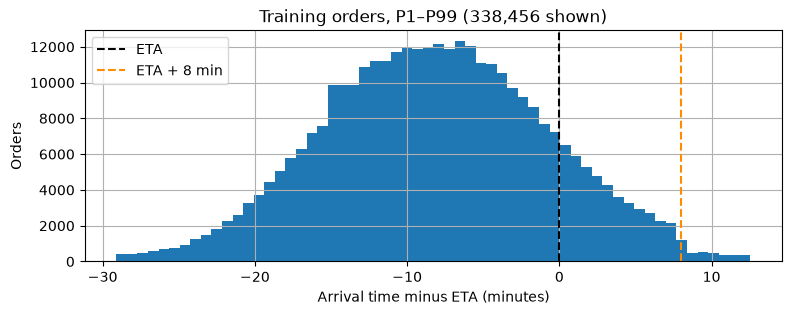

In [20]:
# 仅将直方图显示样本限制在 P1–P99，不改变建模数据。
delay_min = train_numeric["delay_min"]
lower, upper = delay_min.quantile([0.01, 0.99])
visible = delay_min.loc[delay_min.between(lower, upper)]

ax = visible.hist(bins=60, figsize=(9, 3))

ax.axvline(0, color="black", linestyle="--", label="ETA")
ax.axvline(8, color="darkorange", linestyle="--", label="ETA + 8 min")
ax.set_xlabel("Arrival time minus ETA (minutes)")
ax.set_ylabel("Orders")
ax.set_title(f"Training orders, P1–P99 ({len(visible):,} shown)")
ax.legend()
plt.show()


In [21]:
# 统计训练集类别构成；距离区间左闭右开。
category_columns = {
    "预约类型": df_train["is_prebook"].map({0: "非预约", 1: "预约"}),

    "接单日期": df_train["grab_date"].dt.strftime("%Y-%m-%d"),
    "接单小时": df_train["grab_time_dt"].dt.hour,
    "运营区域": df_train["da_id"],

    "商家至顾客距离档": pd.cut(
        df_train["merchant_to_customer_km"],
        bins=[0, 1, 2, 3, 5, np.inf],
        labels=["[0, 1)", "[1, 2)", "[2, 3)", "[3, 5)", "[5, ∞)"],
        right=False,
    ),
}

freq_tables = {}

for name, values in category_columns.items():
    # 保留缺失类别，使频数合计与训练样本数一致。
    counts = values.value_counts(sort=False, dropna=False).sort_index()

    freq_tables[name] = pd.DataFrame({
        "订单数": counts,
        "订单占比(%)": counts / n_train * 100,
    })

display(freq_tables["预约类型"].round(2))
display(freq_tables["接单日期"].round(2))
display(freq_tables["商家至顾客距离档"].round(2))

display(
    freq_tables["接单小时"]
    .nlargest(3, "订单数")
    .round(2)
)

display(
    freq_tables["运营区域"]
    .nlargest(3, "订单数")
    .round(2)
)


,订单数,订单占比(%)
is_prebook,,
非预约,331252,95.92
预约,14103,4.08


,订单数,订单占比(%)
grab_date,,
2022-10-17,66835,19.35
2022-10-18,69095,20.01
2022-10-19,68852,19.94
2022-10-20,68816,19.93
2022-10-21,71757,20.78


,订单数,订单占比(%)
merchant_to_customer_km,,
"[0, 1)",103025,29.83
"[1, 2)",137343,39.77
"[2, 3)",80584,23.33
"[3, 5)",21099,6.11
"[5, ∞)",3304,0.96


,订单数,订单占比(%)
grab_time_dt,,
11,61314,17.75
18,41096,11.90
12,36611,10.60


,订单数,订单占比(%)
da_id,,
0,69976,20.26
9,39082,11.32
5,38493,11.15


训练集的商家至顾客距离主要集中在 2 公里以内，占 69.60%；其中 [1, 2) 公里有 137,343 笔，占 39.77%。接单量最高的小时为北京时间 11:00–11:59，共 61,314 笔，占 17.75%。


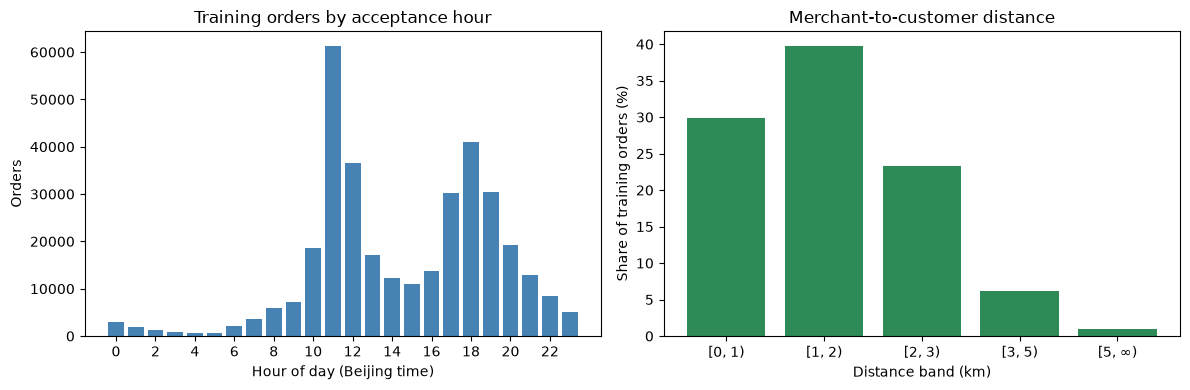

In [22]:
hourly = freq_tables["接单小时"]
distance = freq_tables["商家至顾客距离档"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(hourly.index, hourly["订单数"], color="steelblue")
axes[0].set(
    title="Training orders by acceptance hour",
    xlabel="Hour of day (Beijing time)",
    ylabel="Orders",
    xticks=np.arange(0, 24, 2),
)

axes[1].bar(
    distance.index.astype(str),
    distance["订单占比(%)"],
    color="seagreen",
)
axes[1].set(
    title="Merchant-to-customer distance",
    xlabel="Distance band (km)",
    ylabel="Share of training orders (%)",
)

fig.tight_layout()
plt.show()


图中分别展示接单小时的订单数和距离档的订单占比。时段与距离组的样本量差异较大，后续比较晚到率和错误率时需同时报告各组订单数。


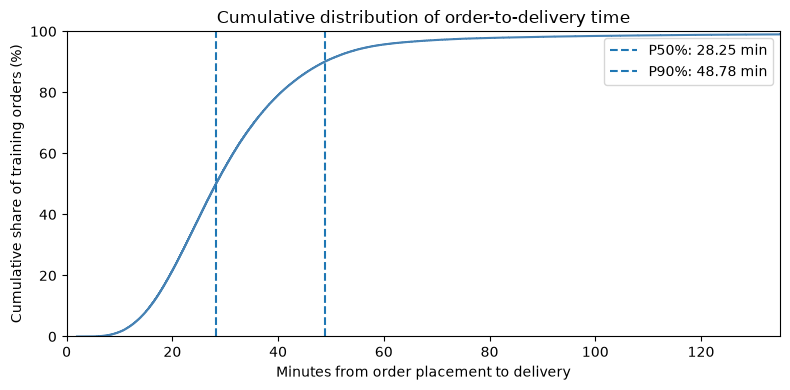

In [23]:
# 累计比例使用全部有效耗时；P99 仅限制横轴显示范围。
duration = train_numeric["order_to_arrive_min"].dropna()
sorted_minutes = duration.sort_values().to_numpy()

cumulative_pct = np.arange(1, len(sorted_minutes) + 1) / len(sorted_minutes) * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.step(sorted_minutes, cumulative_pct, where="post", color="steelblue")

for q in [0.50, 0.90]:
    minutes = duration.quantile(q)
    ax.axvline(minutes, linestyle="--", label=f"P{q:.0%}: {minutes:.2f} min")

ax.set_xlim(0, duration.quantile(0.99))
ax.set_ylim(0, 100)
ax.set(
    title="Cumulative distribution of order-to-delivery time",
    xlabel="Minutes from order placement to delivery",
    ylabel="Cumulative share of training orders (%)",
)
ax.legend()

fig.tight_layout()
plt.show()


训练集中，下单至送达耗时的中位数为 28.25 分钟，P90 为 48.78 分钟。经验累计分布使用全部有效耗时计算，横轴仅显示至 P99。


In [24]:
# 按训练订单汇总组内晚到率，保留缺失类别。
orders = df_train[["y_0", "y_8"]].copy()

orders["hour"] = category_columns["接单小时"]
orders["distance_band"] = category_columns["商家至顾客距离档"]

orders["booking"] = df_train["is_prebook"].map({
    0: "On-demand",
    1: "Prebooked",
})


def summarize_late(by):
    table = orders.groupby(by, observed=True, dropna=False).agg(
        orders=("y_0", "size"),
        late=("y_0", "sum"),
        late_8=("y_8", "sum"),
    )

    table["late_pct"] = 100 * table["late"] / table["orders"]
    table["late_8_pct"] = 100 * table["late_8"] / table["orders"]
    return table


late_by_hour = summarize_late("hour")
late_by_distance = summarize_late("distance_band")
late_by_booking = summarize_late("booking")

late_by_distance_booking = summarize_late(["distance_band", "booking"])

overall_late_pct = orders["y_0"].mean() * 100

display(late_by_hour.loc[[9, 11, 12, 18]].round(2))
display(late_by_distance.round(2))
display(late_by_booking.round(2))
display(late_by_distance_booking.round(2))


,orders,late,late_8,late_pct,late_8_pct
hour,,,,,
9,7185,578,67,8.04,0.93
11,61314,11460,1292,18.69,2.11
12,36611,4448,476,12.15,1.30
18,41096,7879,1088,19.17,2.65


,orders,late,late_8,late_pct,late_8_pct
distance_band,,,,,
"[0, 1)",103025,8683,910,8.43,0.88
"[1, 2)",137343,21664,2155,15.77,1.57
"[2, 3)",80584,16094,2036,19.97,2.53
"[3, 5)",21099,4421,1041,20.95,4.93
"[5, ∞)",3304,658,269,19.92,8.14


,orders,late,late_8,late_pct,late_8_pct
booking,,,,,
On-demand,331252,48606,5983,14.67,1.81
Prebooked,14103,2914,428,20.66,3.03


orders   late  late_8  late_pct  late_8_pct
distance_band booking                                               
[0, 1)        On-demand  100086   8154     857      8.15        0.86
              Prebooked    2939    529      53     18.00        1.80
[1, 2)        On-demand  131840  20574    2047     15.61        1.55
              Prebooked    5503   1090     108     19.81        1.96
[2, 3)        On-demand   76564  15263    1922     19.93        2.51
              Prebooked    4020    831     114     20.67        2.84
[3, 5)        On-demand   19787   4089     955     20.67        4.83
              Prebooked    1312    332      86     25.30        6.55
[5, ∞)        On-demand    2975    526     202     17.68        6.79
              Prebooked     329    132      67     40.12       20.36

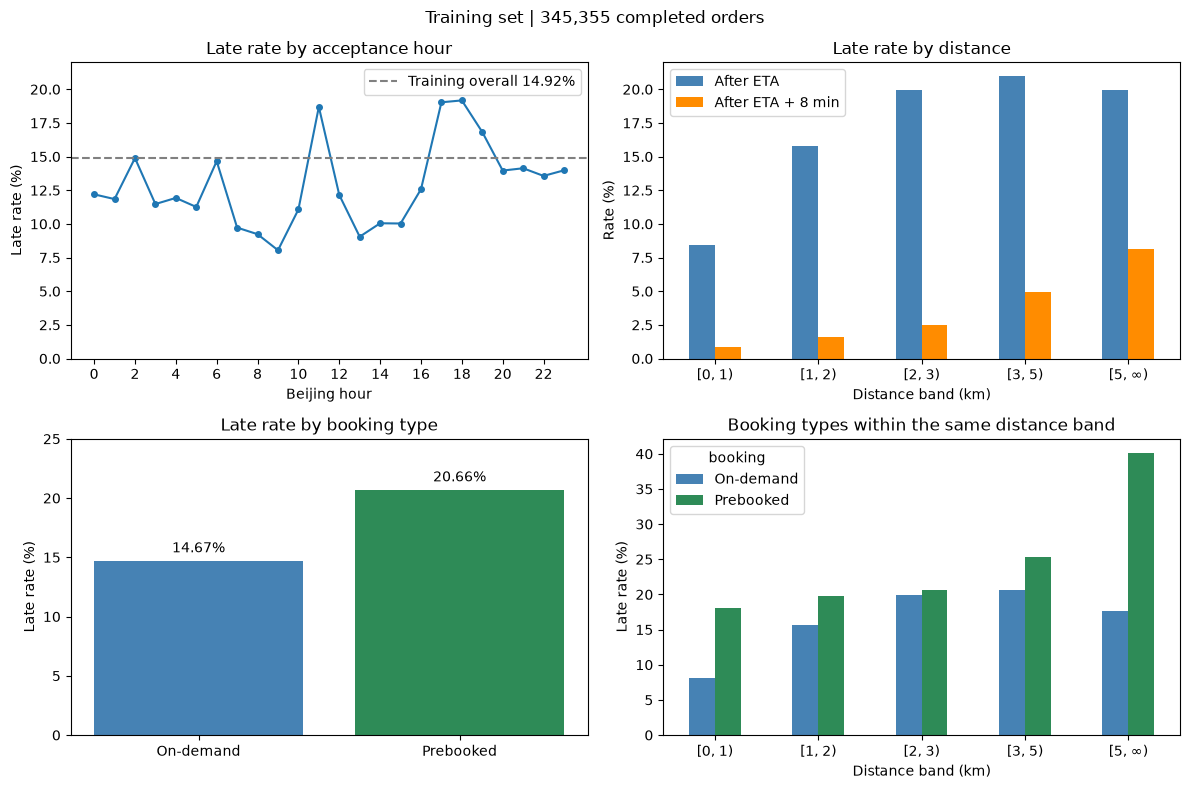

In [25]:
distance_plot = late_by_distance[["late_pct", "late_8_pct"]].rename(
    columns={"late_pct": "After ETA", "late_8_pct": "After ETA + 8 min"}
)

booking_order = ["On-demand", "Prebooked"]

within_distance = (
    late_by_distance_booking["late_pct"]
    .unstack("booking")
    .reindex(index=late_by_distance.index, columns=booking_order)
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

ax = axes[0, 0]
ax.plot(late_by_hour.index, late_by_hour["late_pct"], marker="o", markersize=4)
ax.axhline(
    overall_late_pct, color="gray", linestyle="--",
    label=f"Training overall {overall_late_pct:.2f}%"
)
ax.set(title="Late rate by acceptance hour", xlabel="Beijing hour",
       ylabel="Late rate (%)", xticks=np.arange(0, 24, 2), ylim=(0, 22))
ax.legend()

distance_plot.plot.bar(ax=axes[0, 1], rot=0, color=["steelblue", "darkorange"])
axes[0, 1].set(title="Late rate by distance", xlabel="Distance band (km)",
               ylabel="Rate (%)")

ax = axes[1, 0]
bars = ax.bar(booking_order, late_by_booking.loc[booking_order, "late_pct"],
              color=["steelblue", "seagreen"])
ax.bar_label(bars, fmt="%.2f%%", padding=4)
ax.set(title="Late rate by booking type", ylabel="Late rate (%)", ylim=(0, 25))

within_distance.plot.bar(ax=axes[1, 1], rot=0, color=["steelblue", "seagreen"])
axes[1, 1].set(title="Booking types within the same distance band",
               xlabel="Distance band (km)", ylabel="Late rate (%)")

fig.suptitle(f"Training set | {len(orders):,} completed orders")
fig.tight_layout()
plt.show()


训练集 11 点和 18 点接单订单的 `y_0` 晚到率分别为 18.69% 和 19.17%，均高于总体的 14.92%。11 点接单订单贡献了全部晚到订单的 22.24%；这一比例以全部晚到订单为分母，与该时段的组内晚到率不同。

`y_0` 晚到率在 [3, 5) 公里组最高，为 20.95%；`y_8` 正例率随距离档上升，从 0.88% 增至 8.14%。[1, 2) 公里组有 21,664 笔晚到，占全部晚到订单的 42.05%，其较大订单基数也影响晚到笔数。

预约与非预约订单的 `y_0` 晚到率分别为 20.66% 和 14.67%，相差 5.99 个百分点。各距离档内预约组的晚到率均较高，但差异幅度不一；5 公里及以上的预约组仅有 329 笔。


In [26]:
# 比较五个独立配送阶段；总耗时不作为额外阶段重复计入。
stage_names = {
    "order_to_push_min": "Order → push",
    "push_to_dispatch_min": "Push → dispatch",
    "dispatch_to_grab_min": "Dispatch → accept",
    "grab_to_fetch_min": "Accept → pickup",
    "fetch_to_arrive_min": "Pickup → delivery",
}
segments = list(stage_names)

stage_data = df_train[["y_0", "y_8", "is_prebook"] + segments]

cohorts = {
    "All orders": stage_data,
    "Non-prebooked": stage_data.loc[stage_data["is_prebook"].eq(0)],
    "Prebooked": stage_data.loc[stage_data["is_prebook"].eq(1)],
}


def summarize_stages(frame):
    summary = frame[segments].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90]
    ).T

    summary["valid_n"] = summary["count"].astype(int)
    summary["missing_n"] = len(frame) - summary["valid_n"]

    return summary[
        ["valid_n", "missing_n", "mean", "25%", "50%", "75%", "90%"]
    ]


def compare_stages(label):
    summaries = {}

    for name, frame in cohorts.items():
        summaries[name] = pd.concat({
            0: summarize_stages(frame.loc[frame[label].eq(0)]),
            1: summarize_stages(frame.loc[frame[label].eq(1)]),
        }, names=["status", "stage"])

    # 正值表示晚到组的阶段中位耗时更长。
    gaps = pd.DataFrame({
        name: table.loc[1, "50%"] - table.loc[0, "50%"]
        for name, table in summaries.items()
    }).rename(index=stage_names)

    return summaries, gaps


stage_stats, median_gap = compare_stages("y_0")

display(stage_stats["All orders"].rename(index=stage_names, level="stage").round(2))
display(median_gap.round(2))


valid_n  missing_n   mean    25%    50%    75%  \
status stage                                                               
0      Order → push        293835          0   2.15   0.12   0.20   0.38   
       Push → dispatch     293834          1   6.65   0.35   1.47   4.92   
       Dispatch → accept   293834          1   0.38   0.12   0.18   0.32   
       Accept → pickup     293835          0   9.44   5.38   8.48  12.48   
       Pickup → delivery   293835          0  13.87   7.60  12.20  18.48   
1      Order → push         51520          0   4.09   0.13   0.22   0.53   
       Push → dispatch      51520          0   9.41   0.53   3.40   6.48   
       Dispatch → accept    51520          0   0.72   0.12   0.20   0.38   
       Accept → pickup      51520          0  14.22   7.85  12.80  18.98   
       Pickup → delivery    51520          0  24.06  16.02  23.40  30.93   

                            90%  
status stage                     
0      Order → push        2.40  
       Push → dispatch     8.22  
       Dispatch → accept   0.65  
       Accept → pickup    16.70  
       Pickup → delivery  25.25  
1      Order → push        4.53  
       Push → dispatch    10.93  
       Dispatch → accept   1.07  
       Accept → pickup    25.23  
       Pickup → delivery  38.37

,All orders,Non-prebooked,Prebooked
stage,,,
Order → push,0.02,0.02,0.00
Push → dispatch,1.93,1.83,-2.81
Dispatch → accept,0.02,0.02,0.02
Accept → pickup,4.32,4.18,6.35
Pickup → delivery,11.20,11.30,5.46


下表为训练集中晚到组减去准时组的阶段耗时中位数差，单位为分钟；正值表示晚到组的中位耗时更长。

| 阶段 | 全部订单 | 非预约 | 预约 |
|---|---:|---:|---:|
| 下单 → 推送 | +0.02 | +0.02 | 0.00 |
| 推送 → 派单 | +1.93 | +1.83 | −2.81 |
| 派单 → 接单 | +0.02 | +0.02 | +0.02 |
| 接单 → 取餐 | +4.32 | +4.18 | +6.35 |
| 取餐 → 送达 | +11.20 | +11.30 | +5.46 |


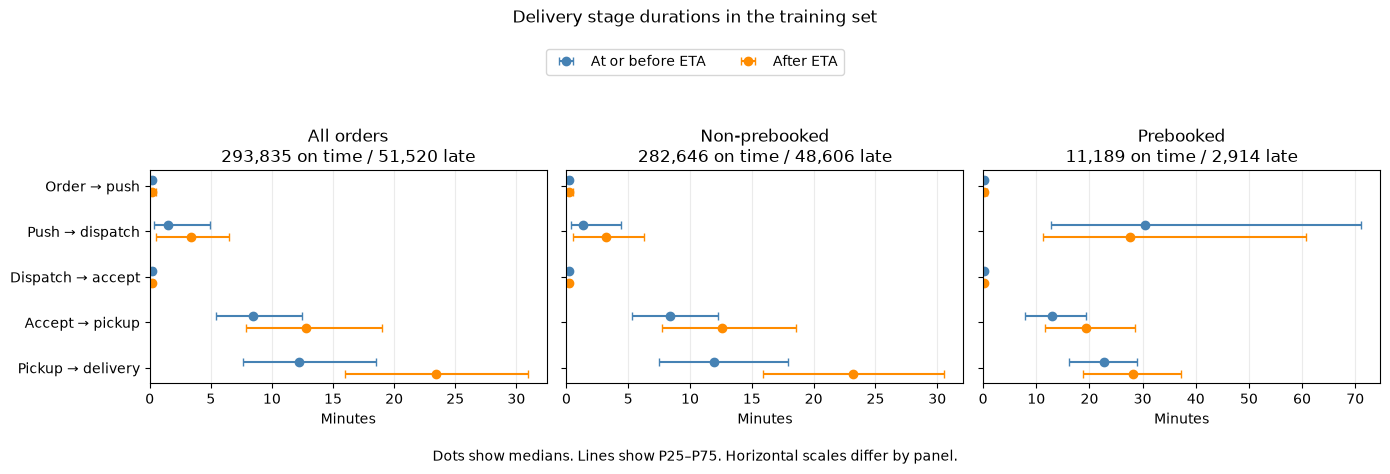

In [27]:
# 点为中位数，误差线为 P25–P75；各面板横轴范围独立。
fig, axes = plt.subplots(1, 3, figsize=(14, 4.7), sharey=True)
y_pos = np.arange(len(segments))

for ax, (name, summary) in zip(axes, stage_stats.items()):
    for status, offset, color, caption in [
        (0, -0.13, "steelblue", "At or before ETA"),
        (1,  0.13, "darkorange", "After ETA"),
    ]:
        table = summary.loc[status].reindex(segments)
        median = table["50%"]

        widths = np.vstack([
            median - table["25%"],
            table["75%"] - median,
        ])

        ax.errorbar(
            median, y_pos + offset,
            xerr=widths, fmt="o", color=color, capsize=3, label=caption,
        )

    on_time_n = cohorts[name]["y_0"].eq(0).sum()
    late_n = cohorts[name]["y_0"].eq(1).sum()
    ax.set_title(f"{name}\n{on_time_n:,} on time / {late_n:,} late")
    ax.set_xlabel("Minutes")
    ax.set_xlim(left=0)
    ax.grid(axis="x", alpha=0.25)

axes[0].set_yticks(y_pos, list(stage_names.values()))
axes[0].invert_yaxis()

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center",
           bbox_to_anchor=(0.5, 0.91), ncol=2)
fig.suptitle("Delivery stage durations in the training set")
fig.text(
    0.5, 0.02,
    "Dots show medians. Lines show P25–P75. Horizontal scales differ by panel.",
    ha="center",
)
fig.tight_layout(rect=[0, 0.06, 1, 0.83])
plt.show()


全部订单中，晚到组与准时组的中位耗时差主要出现在取餐至送达阶段，为 11.20 分钟；接单至取餐阶段相差 4.32 分钟。非预约订单占训练集约 96%，其阶段差异与总体结果接近。

预约订单的最大正向差异出现在接单至取餐阶段，为 6.35 分钟。预约订单推送至派单的中位耗时较长，但晚到组比准时组短 2.81 分钟。阶段本身耗时较长并不意味着该阶段能够解释晚到；这些事后分组差异也不能识别因果机制。图中各面板的横轴尺度不同，应按分钟数比较。


## 5. 特征工程与可得性核查

输入包含 4 个连续特征、4 个类别特征和 4 个数值缺失标记。填补、标准化和类别编码仅在训练集拟合，验证集和测试集复用同一转换器。

| 输入 | 来源与接单时点的关系 |
|---|---|
| 商家至顾客距离 | 商家、顾客坐标描述订单地点，据此估算近似距离 |
| 骑手至商家距离 | `grab_lat`、`grab_lng` 定义为骑手接单时的位置 |
| `dispatch_to_grab_min` | 主表派单时间至接单时间的非负耗时 |
| `push_to_grab_min` | 进入调度系统至接单时间的非负耗时 |
| 接单小时、下单小时 | 从接单、下单时间戳提取北京时间小时 |
| 预约类型、运营区域 | `is_prebook` 和 `da_id` 的订单属性 |

[数据说明论文](<../data/Meituan-INFORMS-TSL-Research-Challenge/Wang-etal-2025_Meituan_Operational-Level On-Demand Food Delivery Data for the 2025 INFORMS TSL Data-Driven Research Challenge.pdf>)第 7–8 页支持事件时间和接单位置的上述定义，并说明坐标经过统一偏移。字段定义支持按接单时点构造输入，但数据未提供在线读取延迟或历史快照，实时可得性仍需部署前验证。

`estimate_arrived_time` 仅用于标签和回溯提前量；现有资料未确认它是否为接单时可见的 ETA 版本。`fetch_time`、`arrive_time` 及接单后的阶段耗时不进入模型。


In [28]:
# 按接单时点的字段定义构造特征；距离为公里，耗时为分钟。
numeric_features = [
    "merchant_to_customer_km",
    "rider_to_merchant_km",
    "dispatch_to_grab_min",
    "push_to_grab_min",
]

categorical_features = ["grab_hour", "order_hour", "is_prebook", "da_id"]

missing_flags = [f"{col}_missing" for col in numeric_features]
feature_cols = numeric_features + categorical_features + missing_flags


def build_features(frame):
    # 显式选列，排除 ETA、实际送达及接单后的阶段耗时。
    X = frame[[
        "merchant_to_customer_km", "rider_to_merchant_km",
        "dispatch_to_grab_min", "is_prebook", "da_id",
    ]].copy()

    X["grab_hour"] = frame["grab_time_dt"].dt.hour
    X["order_hour"] = frame["platform_order_time_dt"].dt.hour

    # 负耗时保留为缺失，缺失标记在填补前生成。
    minutes = (frame["grab_time"] - frame["order_push_time"]) / 60
    X["push_to_grab_min"] = minutes.where(minutes.ge(0))

    for col in numeric_features:
        X[f"{col}_missing"] = X[col].isna().astype("int8")

    for col in categorical_features:
        X[col] = X[col].astype("string").fillna("Missing").astype(str)

    # 固定列顺序以保证三个数据集一致。
    return X[feature_cols]


X_train = build_features(df_train)
X_val = build_features(df_val)
X_test = build_features(df_test)

target_cols = ["y_0", "y_8"]
y_train = df_train[target_cols].copy()
y_val = df_val[target_cols].copy()
y_test = df_test[target_cols].copy()

for name, X, y in [
    ("train", X_train, y_train),
    ("val", X_val, y_val),
    ("test", X_test, y_test),
]:
    print(name, "X:", X.shape, "y:", y.shape, "索引对齐:", X.index.equals(y.index))

display(X_train[numeric_features].isna().sum().to_frame("训练集缺失数"))


train X: (345355, 12) y: (345355, 2) 索引对齐: True
val X: (77230, 12) y: (77230, 2) 索引对齐: True
test X: (145068, 12) y: (145068, 2) 索引对齐: True


,训练集缺失数
merchant_to_customer_km,0
rider_to_merchant_km,0
dispatch_to_grab_min,1
push_to_grab_min,0


### 极端耗时核查


In [29]:
duration_features = ["dispatch_to_grab_min", "push_to_grab_min"]
audit_feature_sets = {"Train": X_train, "Validation": X_val, "Test": X_test}
duration_audit_tables = {}

for split, features in audit_feature_sets.items():
    table = features[duration_features].describe(percentiles=[0.99, 0.995]).T
    table["missing"] = features[duration_features].isna().sum()
    duration_audit_tables[split] = table[["count", "missing", "99%", "99.5%", "max"]]

duration_audit_summary = pd.concat(
    duration_audit_tables, names=["split", "feature"]
)
display(duration_audit_summary.round(4))

# 仅核查已进入训练、验证或测试的订单，保留原始事件时间。
audit_features = pd.concat(audit_feature_sets, names=["split", "row_index"])
audit_record_cols = [
    "order_id", "is_prebook", "platform_order_time_dt", "order_push_time_dt",
    "dispatch_time_dt", "grab_time_dt", "fetch_time_dt", "arrive_time_dt",
]
extreme_duration_tables = {}
for feature in duration_features:
    largest = audit_features[feature].nlargest(3)
    records = df_clean.loc[largest.index.get_level_values("row_index"), audit_record_cols].copy()
    records.insert(0, "split", largest.index.get_level_values("split"))
    records["duration_min"] = largest.to_numpy()
    extreme_duration_tables[feature] = records

extreme_duration_records = pd.concat(
    extreme_duration_tables, names=["feature", "row_index"]
)
display(extreme_duration_records)


count  missing      99%     99.5%  \
split      feature                                                      
Train      dispatch_to_grab_min  345354.0        1   4.8667    7.1500   
           push_to_grab_min      345355.0        0  71.0730  158.4640   
Validation dispatch_to_grab_min   77230.0        0   4.5785    6.3476   
           push_to_grab_min       77230.0        0  65.4355  143.1407   
Test       dispatch_to_grab_min  145068.0        0   5.0333    7.3222   
           push_to_grab_min      145068.0        0  57.9943  124.6547   

                                        max  
split      feature                           
Train      dispatch_to_grab_min    319.7667  
           push_to_grab_min       8634.2000  
Validation dispatch_to_grab_min     42.7500  
           push_to_grab_min      10293.1167  
Test       dispatch_to_grab_min    111.3167  
           push_to_grab_min       6110.1500

split  order_id  is_prebook  \
feature              row_index                                     
dispatch_to_grab_min 259043          Train    242141           1   
                     233025          Train    219102           1   
                     238375           Test    223856           1   
push_to_grab_min     24716      Validation     24526           1   
                     391494     Validation    356027           1   
                     285121          Train    265059           1   

                                  platform_order_time_dt  \
feature              row_index                             
dispatch_to_grab_min 259043    2022-10-17 23:46:38+08:00   
                     233025    2022-10-18 14:12:53+08:00   
                     238375    2022-10-23 16:37:42+08:00   
push_to_grab_min     24716     2022-10-15 07:33:56+08:00   
                     391494    2022-10-15 09:36:05+08:00   
                     285121    2022-10-12 11:18:07+08:00   

                                      order_push_time_dt  \
feature              row_index                             
dispatch_to_grab_min 259043    2022-10-17 23:46:53+08:00   
                     233025    2022-10-18 14:12:59+08:00   
                     238375    2022-10-23 16:38:02+08:00   
push_to_grab_min     24716     2022-10-15 07:34:17+08:00   
                     391494    2022-10-15 09:36:17+08:00   
                     285121    2022-10-12 11:18:19+08:00   

                                        dispatch_time_dt  \
feature              row_index                             
dispatch_to_grab_min 259043    2022-10-18 00:53:27+08:00   
                     233025    2022-10-18 15:22:59+08:00   
                     238375    2022-10-23 16:38:02+08:00   
push_to_grab_min     24716     2022-10-22 11:07:02+08:00   
                     391494    2022-10-22 10:54:32+08:00   
                     285121    2022-10-18 11:11:51+08:00   

                                            grab_time_dt  \
feature              row_index                             
dispatch_to_grab_min 259043    2022-10-18 06:13:13+08:00   
                     233025    2022-10-18 17:24:15+08:00   
                     238375    2022-10-23 18:29:21+08:00   
push_to_grab_min     24716     2022-10-22 11:07:24+08:00   
                     391494    2022-10-22 10:58:54+08:00   
                     285121    2022-10-18 11:12:31+08:00   

                                           fetch_time_dt  \
feature              row_index                             
dispatch_to_grab_min 259043    2022-10-18 10:49:04+08:00   
                     233025    2022-10-18 17:24:46+08:00   
                     238375    2022-10-23 18:31:19+08:00   
push_to_grab_min     24716     2022-10-22 11:15:18+08:00   
                     391494    2022-10-22 11:12:15+08:00   
                     285121    2022-10-18 11:23:07+08:00   

                                          arrive_time_dt  duration_min  
feature              row_index                                          
dispatch_to_grab_min 259043    2022-10-18 11:14:25+08:00    319.766667  
                     233025    2022-10-18 18:15:11+08:00    121.266667  
                     238375    2022-10-23 18:46:46+08:00    111.316667  
push_to_grab_min     24716     2022-10-22 11:50:25+08:00  10293.116667  
                     391494    2022-10-22 11:43:05+08:00  10162.616667  
                     285121    2022-10-18 11:50:03+08:00   8634.200000

训练集派单至接单耗时的 P99 为 4.87 分钟，P99.5 为 7.15 分钟，最大值为 319.77 分钟；推送至接单耗时的对应值为 71.07、158.46 和 8,634.20 分钟。验证集推送至接单的最大值为 10,293.12 分钟：订单 24526 的推送时间为 10 月 15 日 07:34:17，接单时间为 10 月 22 日 11:07:24（北京时间）。

所列极端记录均为预约订单，部分存在跨日的长时间间隔，但所检查的事件顺序未出现倒置。时间顺序一致并不能确认业务记录真实有效；现有资料不足以区分长等待、重入调度或记录问题。未发现足以制定纠错规则的证据，因此保留这些正值，不进行截尾或删除，其有效性仍是数据限制。


In [30]:
# 填补、标准化和类别编码仅在训练集拟合。
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),

    # 未见类别编码为全零；缺失标记直接传递。
    ("category", OneHotEncoder(handle_unknown="ignore"), categorical_features),

    ("flag", "passthrough", missing_flags),
])

X_train_ready = preprocessor.fit_transform(X_train)

# 验证集只转换，不重新拟合预处理参数。
X_val_ready = preprocessor.transform(X_val)

imputer = preprocessor.named_transformers_["numeric"].named_steps["imputer"]
train_medians = pd.Series(
    imputer.statistics_, index=numeric_features, name="训练集中位数",
)
display(train_medians.round(4).to_frame())

encoder = preprocessor.named_transformers_["category"]
category_sizes = pd.Series(
    [len(values) for values in encoder.categories_],
    index=categorical_features,
    name="训练集类别数",
)
display(category_sizes.to_frame())

print("转换后训练集:", X_train_ready.shape)
print("转换后验证集:", X_val_ready.shape)


,训练集中位数
merchant_to_customer_km,1.4714
rider_to_merchant_km,0.4639
dispatch_to_grab_min,0.1833
push_to_grab_min,2.2167


,训练集类别数
grab_hour,24
order_hour,24
is_prebook,2
da_id,23


转换后训练集: (345355, 81)
转换后验证集: (77230, 81)


## 6. 基准与模型比较

随机基准使用固定随机种子，距离规则按商家至顾客距离排序。Logistic Regression 与 XGBoost 使用相同预处理特征，均只在训练集拟合；参数预先固定，未进行大规模搜索。主分析以 `y_0` 的验证集 AP 和 ROC-AUC 比较排序能力，再检验指定监控容量下的结果。


In [31]:
# 先按订单 ID 排序，再生成固定种子的随机基准分数。
val_baselines = df_val[["order_id", "y_0", "y_8"]].sort_values("order_id").copy()

rng = np.random.default_rng(RANDOM_SEED)
val_baselines["random_score"] = rng.random(len(val_baselines))

# 距离缺失用训练中位数填补，按原始索引对齐。
val_baselines["distance_score_km"] = X_val["merchant_to_customer_km"].fillna(
    train_medians["merchant_to_customer_km"]
)

# 两个标签复用基准分数，分别评估。
rows = []
for target in target_cols:
    truth = val_baselines[target]

    for method, score_col in [
        ("Random", "random_score"),
        ("Distance", "distance_score_km"),
    ]:
        scores = val_baselines[score_col]

        rows.append({
            "label": target,
            "method": method,
            "positive_rate": truth.mean(),
            "AP": average_precision_score(truth, scores),
            "ROC-AUC": roc_auc_score(truth, scores),
        })

baseline_metrics = pd.DataFrame(rows)
display(val_baselines.head(3).round(4))
display(baseline_metrics.round(5))


,order_id,y_0,y_8,random_score,distance_score_km
1960,1960,0,0,0.7740,0.1739
1961,1961,0,0,0.4389,0.4422
1962,1962,0,0,0.8586,0.9121


,label,method,positive_rate,AP,ROC-AUC
0,y_0,Random,0.15093,0.15103,0.49867
1,y_0,Distance,0.15093,0.19547,0.60727
2,y_8,Random,0.01924,0.01901,0.49532
3,y_8,Distance,0.01924,0.04586,0.67124


In [32]:
# 以 y_0 拟合固定参数的 Logistic Regression。
target = "y_0"

lr_model = LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000)

lr_model.fit(X_train_ready, y_train[target])

print("类别顺序:", lr_model.classes_)
print("实际迭代次数:", lr_model.n_iter_[0])

# 保存正类分数并恢复原始索引，便于与其他方法对齐。
lr_val_score = pd.Series(
    lr_model.predict_proba(X_val_ready)[:, 1],
    index=X_val.index,
    name="logistic_score",
)

print("验证分数条数:", len(lr_val_score))
display(lr_val_score.head().round(5))


类别顺序: [0 1]
实际迭代次数: 47
验证分数条数: 77230


1960    0.09304
1961    0.08228
1962    0.08148
1963    0.12134
1964    0.04851
Name: logistic_score, dtype: float64

In [33]:
# 使用 float32 稠密输入，显式保留零值，避免与缺失值混淆。
X_train_xgb = X_train_ready.astype(np.float32).toarray()
X_val_xgb = X_val_ready.astype(np.float32).toarray()

xgb_model = XGBClassifier(
    objective="binary:logistic",
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    tree_method="hist",
    random_state=RANDOM_SEED,
    n_jobs=4,
)

xgb_model.fit(X_train_xgb, y_train[target])

xgb_val_score = pd.Series(
    xgb_model.predict_proba(X_val_xgb)[:, 1],
    index=X_val.index,
    name="xgboost_score",
)

print("训练矩阵:", X_train_xgb.shape)
print("验证矩阵:", X_val_xgb.shape)
print("实际训练轮数:", xgb_model.get_booster().num_boosted_rounds())
display(xgb_val_score.head().round(5))


训练矩阵: (345355, 81)
验证矩阵: (77230, 81)
实际训练轮数: 200


1960    0.10111
1961    0.07276
1962    0.07418
1963    0.20965
1964    0.12281
Name: xgboost_score, dtype: float32

In [34]:
# 按原始行索引合并验证分数，检查完整性后比较排序指标。
validation_scores = val_baselines.copy()
validation_scores["logistic_score"] = lr_val_score
validation_scores["xgboost_score"] = xgb_val_score

score_columns = {
    "Random": "random_score",
    "Distance": "distance_score_km",
    "Logistic Regression": "logistic_score",
    "XGBoost": "xgboost_score",
}

assert len(validation_scores) == len(X_val)
assert validation_scores[list(score_columns.values())].notna().all().all()

truth = validation_scores[target]

comparison_rows = []
for method, col in score_columns.items():
    scores = validation_scores[col]
    comparison_rows.append({
        "method": method,
        "AP": average_precision_score(truth, scores),
        "ROC-AUC": roc_auc_score(truth, scores),
    })

model_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("AP", ascending=False, ignore_index=True)
)

print(f"验证集正例率: {truth.mean():.2%}")
display(model_comparison.round(5))


验证集正例率: 15.09%


,method,AP,ROC-AUC
0,XGBoost,0.27148,0.68084
1,Logistic Regression,0.25027,0.65759
2,Distance,0.19547,0.60727
3,Random,0.15103,0.49867


验证集上，XGBoost 的 AP 为 0.27148，高于 Logistic Regression 的 0.25027、距离规则的 0.19547 和随机基准的 0.15103。随机基准的 AP 接近该集正例率 15.09%。AP 汇总不同召回水平下的排序表现。

XGBoost 的 ROC-AUC 为 0.68084，表示随机抽取一笔晚到订单和一笔准时订单时，模型将晚到订单排在前面的比例约为 68.08%，同分计半。XGBoost 在本验证集的两项指标上均领先；后续使用固定阈值检验其在测试期的表现。


## 7. 监控容量与阈值选择

验证集先按分数降序选取前 `ceil(n × q)` 笔，比较 5%、10%、20% 的目标监控比例；同分按订单 ID 排序。精确率为命中数除以监控数，覆盖率（Recall）为命中数除以实际晚到数。

随后在验证集上选择可用于逐单判断的分数阈值并固定，在测试集检验其实际工作量。


In [35]:
# 按分数选取前 ceil(n × q) 笔；同分按订单 ID 排序。
from math import ceil

capacity_target = "y_0"
capacities = [5, 10, 20]

n_orders = len(validation_scores)
n_late = int(validation_scores[capacity_target].sum())

capacity_rows = []

for method, score_col in score_columns.items():
    ranked = validation_scores.sort_values(
        [score_col, "order_id"],
        ascending=[False, True],
    )

    for capacity in capacities:
        k = ceil(n_orders * capacity / 100)

        selected = ranked.head(k)

        hits = int(selected[capacity_target].sum())

        capacity_rows.append({
            "capacity_pct": capacity,
            "method": method,
            "monitored": k,
            "hits": hits,
            "precision_pct": 100 * hits / k,
            "coverage_pct": 100 * hits / n_late,
        })

validation_topq = (
    pd.DataFrame(capacity_rows)
    .sort_values(["capacity_pct", "hits"], ascending=[True, False], ignore_index=True)
)

print(f"验证集订单 {n_orders:,} 笔，其中晚到 {n_late:,} 笔")
display(validation_topq.round(2))


验证集订单 77,230 笔，其中晚到 11,656 笔


,capacity_pct,method,monitored,hits,precision_pct,coverage_pct
0,5,XGBoost,3862,1387,35.91,11.90
1,5,Logistic Regression,3862,1288,33.35,11.05
2,5,Distance,3862,815,21.10,6.99
3,5,Random,3862,596,15.43,5.11
4,10,XGBoost,7723,2441,31.61,20.94
5,10,Logistic Regression,7723,2230,28.87,19.13
6,10,Distance,7723,1645,21.30,14.11
7,10,Random,7723,1135,14.70,9.74
8,20,XGBoost,15446,4159,26.93,35.68
9,20,Logistic Regression,15446,4001,25.90,34.33


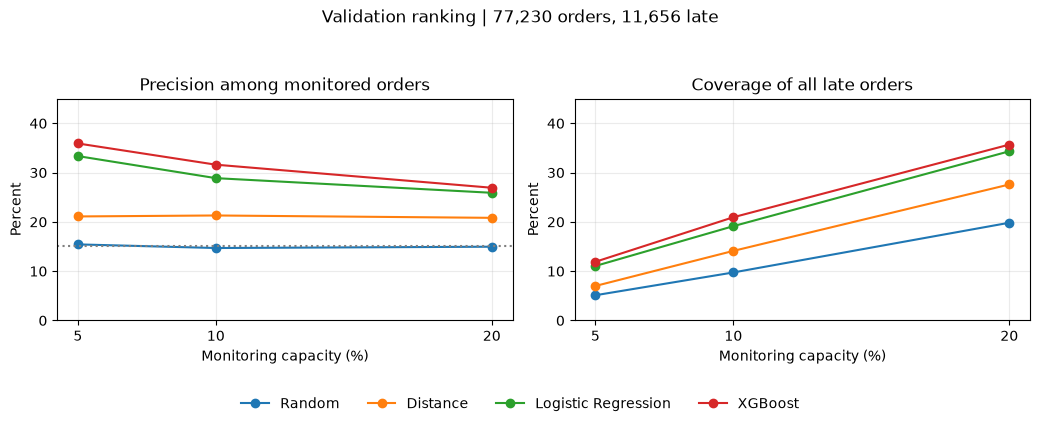

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))

for method in score_columns:
    points = validation_topq.loc[
        validation_topq["method"].eq(method)
    ].sort_values("capacity_pct")

    axes[0].plot(
        points["capacity_pct"], points["precision_pct"], marker="o", label=method
    )
    axes[1].plot(
        points["capacity_pct"], points["coverage_pct"], marker="o", label=method
    )

for ax, title in zip(axes, [
    "Precision among monitored orders",
    "Coverage of all late orders",
]):
    ax.set(
        title=title, xlabel="Monitoring capacity (%)",
        ylabel="Percent", xticks=capacities, ylim=(0, 45),
    )
    ax.grid(alpha=0.25)

axes[0].axhline(100 * n_late / n_orders, color="gray", linestyle=":")

handles, labels = axes[0].get_legend_handles_labels()
fig.suptitle(f"Validation ranking | {n_orders:,} orders, {n_late:,} late")
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=[0, 0.10, 1, 0.93])
plt.show()


验证集按排名监控前 10% 的订单时，XGBoost 的精确率为 31.61%，覆盖率为 20.94%；随机基准覆盖率为 9.74%。将 XGBoost 的监控比例增至 20%，需多监控 7,723 笔订单，多命中 1,718 笔，覆盖率增至 35.68%，精确率降至 26.93%。扩大监控范围提高了晚到识别量，同时降低了单位监控量的命中比例。


In [37]:
# 同分订单整体纳入，选择验证监控量最接近目标的阈值。
def choose_threshold(scores, capacity_pct):
    score_counts = scores.value_counts().sort_index(ascending=False)

    monitored_by_threshold = score_counts.cumsum()

    # 加入不预警的候选规则。
    monitored_by_threshold = pd.concat([
        pd.Series([0], index=[np.inf]),
        monitored_by_threshold,
    ])

    # 使用整数尺度比较偏差；同距时取更高阈值，监控量更小。
    gap = (100 * monitored_by_threshold - capacity_pct * len(scores)).abs()

    threshold = gap.idxmin()
    monitored = int(monitored_by_threshold.loc[threshold])
    return float(threshold), monitored


threshold_rows = []

for method, score_col in score_columns.items():
    scores = validation_scores[score_col]
    for capacity in capacities:
        threshold, monitored = choose_threshold(scores, capacity)
        threshold_rows.append({
            "method": method,
            "score_col": score_col,
            "target_pct": capacity,
            "threshold": threshold,
            "val_monitored": monitored,
            "val_actual_pct": 100 * monitored / len(scores),
        })

validation_thresholds = pd.DataFrame(threshold_rows)

display(validation_thresholds.round(6))


,method,score_col,target_pct,threshold,val_monitored,val_actual_pct
0,Random,random_score,5,0.949985,3861,4.999353
1,Random,random_score,10,0.900278,7723,10.000000
2,Random,random_score,20,0.799149,15446,20.000000
3,Distance,distance_score_km,5,3.274271,3861,4.999353
4,Distance,distance_score_km,10,2.803598,7723,10.000000
5,Distance,distance_score_km,20,2.346175,15446,20.000000
6,Logistic Regression,logistic_score,5,0.282332,3861,4.999353
7,Logistic Regression,logistic_score,10,0.240336,7723,10.000000
8,Logistic Regression,logistic_score,20,0.201616,15446,20.000000
9,XGBoost,xgboost_score,5,0.293203,3861,4.999353


阈值仅根据验证集分数确定，使 `score >= threshold` 对应的监控量尽可能接近目标比例。同分订单一起纳入；若两个阈值与目标同样接近，采用监控量较小的阈值。因此，这一规则与严格选取前 k 笔的排名评估可能略有差异。

| 方法 | 5% 目标阈值 | 10% 目标阈值 | 20% 目标阈值 |
|---|---:|---:|---:|
| 随机 | 0.949985 | 0.900278 | 0.799149 |
| 距离 | 3.274271 | 2.803598 | 2.346175 |
| Logistic Regression | 0.282332 | 0.240336 | 0.201616 |
| XGBoost | 0.293203 | 0.256661 | 0.215594 |



## 8. 固定阈值的测试集评估

模型、预处理参数和阈值均在进入测试集前固定。以下按验证目标容量列示结果，并分别报告测试期实际监控率、精确率和覆盖率。


In [38]:
# 测试集复用训练预处理、模型及验证阈值。
X_test_ready = preprocessor.transform(X_test)

X_test_xgb = X_test_ready.astype(np.float32).toarray()

test_scores = df_test[["order_id", "grab_date"]].sort_values("order_id").copy()

test_scores["logistic_score"] = pd.Series(
    lr_model.predict_proba(X_test_ready)[:, 1], index=X_test.index,
)
test_scores["xgboost_score"] = pd.Series(
    xgb_model.predict_proba(X_test_xgb)[:, 1], index=X_test.index,
)

test_scores["distance_score_km"] = X_test["merchant_to_customer_km"].fillna(
    train_medians["merchant_to_customer_km"]
)

# 延续验证集后的随机序列，避免重复使用同一段随机分数。
rng_fixed = np.random.default_rng(RANDOM_SEED)
rng_fixed.random(len(validation_scores))
test_scores["random_score"] = rng_fixed.random(len(test_scores))

test_scores[capacity_target] = y_test[capacity_target]

print(f"测试订单：{len(test_scores):,}")
print(f"实际晚到：{test_scores[capacity_target].sum():,}")


测试订单：145,068
实际晚到：21,922


In [39]:
# 固定验证阈值，分别报告实际工作量、精确率和覆盖率。
def evaluate_thresholds(score_table):
    late = score_table[capacity_target].eq(1)
    total_late = int(late.sum())
    n = len(score_table)
    rows = []

    for rule in validation_thresholds.itertuples(index=False):
        monitored_mask = score_table[rule.score_col].ge(rule.threshold)
        monitored = int(monitored_mask.sum())

        hits = int((monitored_mask & late).sum())

        # 无预警或无正例时，对应比例记为缺失。
        rows.append({
            "target_pct": rule.target_pct,
            "method": rule.method,
            "monitored": monitored,
            "actual_pct": 100 * monitored / n,
            "hits": hits,
            "precision_pct": 100 * hits / monitored if monitored else np.nan,
            "coverage_pct": 100 * hits / total_late if total_late else np.nan,
        })

    return pd.DataFrame(rows).sort_values(
        ["target_pct", "hits"], ascending=[True, False], ignore_index=True,
    )


test_fixed = evaluate_thresholds(test_scores)
display(test_fixed.round(2))


,target_pct,method,monitored,actual_pct,hits,precision_pct,coverage_pct
0,5,XGBoost,7549,5.20,2548,33.75,11.62
1,5,Logistic Regression,7670,5.29,2471,32.22,11.27
2,5,Distance,7400,5.10,1610,21.76,7.34
3,5,Random,7305,5.04,1060,14.51,4.84
4,10,XGBoost,15117,10.42,4537,30.01,20.70
5,10,Logistic Regression,15385,10.61,4404,28.63,20.09
6,10,Distance,14439,9.95,3169,21.95,14.46
7,10,Random,14572,10.04,2143,14.71,9.78
8,20,XGBoost,29625,20.42,7904,26.68,36.06
9,20,Logistic Regression,30023,20.70,7597,25.30,34.65


XGBoost 在验证集上按 10% 目标容量确定阈值 0.2566608489。该阈值固定应用于测试集后，145,068 笔订单中有 15,117 笔触发预警，其中 4,537 笔实际晚到：

- 实际监控率为 15,117 / 145,068 = **10.42%**，反映测试期的监控工作量。
- 精确率为 4,537 / 15,117 = **30.01%**，反映预警订单中的晚到比例。
- 覆盖率为 4,537 / 21,922 = **20.70%**，反映全部晚到订单中被识别的比例。

实际监控率高于验证目标，说明固定阈值下测试集的分数分布有所不同。同为 10% 验证目标，XGBoost 比 Logistic Regression 少监控 268 笔、多命中 133 笔；比距离规则多监控 678 笔、多命中 1,368 笔。


In [40]:
# 逐日使用同一组阈值；跨日比例需按汇总分子、分母重算。
test_by_day = pd.concat(
    {
        date.strftime("%Y-%m-%d"): evaluate_thresholds(day_scores)
        for date, day_scores in test_scores.groupby("grab_date")
    },
    names=["date"],
).reset_index(level="date").reset_index(drop=True)

display(test_by_day.loc[test_by_day["target_pct"].eq(10)].round(2))


,date,target_pct,method,monitored,actual_pct,hits,precision_pct,coverage_pct
4,2022-10-23,10,XGBoost,8384,10.79,2685,32.03,20.80
5,2022-10-23,10,Logistic Regression,8351,10.75,2612,31.28,20.24
6,2022-10-23,10,Distance,7761,9.99,1921,24.75,14.88
7,2022-10-23,10,Random,7699,9.91,1221,15.86,9.46
16,2022-10-24,10,XGBoost,6733,10.00,1852,27.51,20.55
17,2022-10-24,10,Logistic Regression,7034,10.44,1792,25.48,19.88
18,2022-10-24,10,Distance,6678,9.92,1248,18.69,13.85
19,2022-10-24,10,Random,6873,10.21,922,13.41,10.23


同一 XGBoost 阈值在 10 月 23 日和 24 日的实际监控率分别为 10.79% 和 10.00%，命中数分别为 2,685 和 1,852。固定阈值对应的每日工作量会变化。跨日汇总比例按总分子除以总分母计算，不取每日比例的简单平均；两天的结果不足以判断长期稳定性。


## 9. `y_8` 敏感性分析

将目标改为超过 ETA 8 分钟后，使用相同特征、训练窗口和 XGBoost 超参数单独拟合模型，并在 `y_8` 验证分数上选择阈值。随机与距离基准复用原分数和阈值，其评价标签改为 `y_8`；本节不将 `y_0` 模型分数解释为严重延迟概率。


In [41]:
# 沿用主模型超参数，为 y_8 独立拟合 XGBoost。
from sklearn.base import clone

target_y8 = "y_8"

xgb_y8_model = clone(xgb_model)

xgb_y8_model.fit(X_train_xgb, y_train[target_y8])

val_scores_y8 = validation_scores[
    ["order_id", target_y8, "random_score", "distance_score_km"]
].copy()

val_scores_y8["xgboost_y8_score"] = pd.Series(
    xgb_y8_model.predict_proba(X_val_xgb)[:, 1],
    index=X_val.index,
)

print(f"训练集 y_8 正例：{y_train[target_y8].sum():,} / {len(y_train):,}")
print(f"验证集 y_8 正例：{val_scores_y8[target_y8].sum():,} / {len(val_scores_y8):,}")
print(f"实际训练轮数：{xgb_y8_model.get_booster().num_boosted_rounds()}")


训练集 y_8 正例：6,411 / 345,355
验证集 y_8 正例：1,486 / 77,230
实际训练轮数：200


In [42]:
# y_8 模型阈值按其验证分数选择；随机与距离规则复用原阈值。
y8_rows = []
y8_score_col = "xgboost_y8_score"

for capacity in capacities:
    threshold, monitored = choose_threshold(
        val_scores_y8[y8_score_col], capacity
    )
    y8_rows.append({
        "method": "XGBoost (y_8)",
        "score_col": y8_score_col,
        "target_pct": capacity,
        "threshold": threshold,
        "val_monitored": monitored,
        "val_actual_pct": 100 * monitored / len(val_scores_y8),
    })

rule_thresholds = validation_thresholds.loc[
    validation_thresholds["method"].isin(["Random", "Distance"])
].copy()

thresholds_y8 = pd.concat(
    [rule_thresholds, pd.DataFrame(y8_rows)], ignore_index=True
)

display(thresholds_y8.round(6))


,method,score_col,target_pct,threshold,val_monitored,val_actual_pct
0,Random,random_score,5,0.949985,3861,4.999353
1,Random,random_score,10,0.900278,7723,10.000000
2,Random,random_score,20,0.799149,15446,20.000000
3,Distance,distance_score_km,5,3.274271,3861,4.999353
4,Distance,distance_score_km,10,2.803598,7723,10.000000
5,Distance,distance_score_km,20,2.346175,15446,20.000000
6,XGBoost (y_8),xgboost_y8_score,5,0.056263,3861,4.999353
7,XGBoost (y_8),xgboost_y8_score,10,0.035996,7723,10.000000
8,XGBoost (y_8),xgboost_y8_score,20,0.022374,15446,20.000000


In [43]:
# 测试标签统一为 y_8；保留各方法的实际监控量。
test_scores_y8 = test_scores[
    ["order_id", "grab_date", "random_score", "distance_score_km"]
].copy()

test_scores_y8["xgboost_y8_score"] = pd.Series(
    xgb_y8_model.predict_proba(X_test_xgb)[:, 1],
    index=X_test.index,
)
test_scores_y8[target_y8] = y_test[target_y8]


def evaluate_fixed_rules(score_table, rules, label_col):
    late = score_table[label_col].eq(1)
    n_orders = len(score_table)
    n_late = int(late.sum())
    rows = []

    for rule in rules.itertuples(index=False):
        monitored_mask = score_table[rule.score_col].ge(rule.threshold)
        monitored = int(monitored_mask.sum())

        hits = int((monitored_mask & late).sum())

        rows.append({
            "target_pct": rule.target_pct,
            "method": rule.method,
            "monitored": monitored,
            "actual_pct": 100 * monitored / n_orders,
            "hits": hits,
            "precision_pct": 100 * hits / monitored if monitored else np.nan,
            "coverage_pct": 100 * hits / n_late if n_late else np.nan,
        })

    return pd.DataFrame(rows).sort_values(
        ["target_pct", "hits"],
        ascending=[True, False],
        ignore_index=True,
    )


test_fixed_y8 = evaluate_fixed_rules(test_scores_y8, thresholds_y8, target_y8)
print(f"测试集 y_8 正例：{test_scores_y8[target_y8].sum():,} / {len(test_scores_y8):,}")
display(test_fixed_y8.round(2))


测试集 y_8 正例：2,963 / 145,068


,target_pct,method,monitored,actual_pct,hits,precision_pct,coverage_pct
0,5,XGBoost (y_8),7416,5.11,1041,14.04,35.13
1,5,Distance,7400,5.10,577,7.80,19.47
2,5,Random,7305,5.04,153,2.09,5.16
3,10,XGBoost (y_8),15013,10.35,1423,9.48,48.03
4,10,Distance,14439,9.95,846,5.86,28.55
5,10,Random,14572,10.04,286,1.96,9.65
6,20,XGBoost (y_8),30167,20.80,1836,6.09,61.96
7,20,Distance,29315,20.21,1245,4.25,42.02
8,20,Random,29107,20.06,615,2.11,20.76


`y_8` 测试集共有 2,963 笔正例。采用该标签单独训练的 XGBoost 及其 10% 验证目标阈值时，测试集预警 15,013 笔，实际监控率为 10.35%，命中 1,423 笔。精确率为 9.48%，覆盖率为 48.03%。

在 `y_8` 的三个目标容量下，XGBoost 的精确率和覆盖率均高于随机及距离基准。5% 目标下，XGBoost 比距离规则多监控 16 笔、多命中 464 笔；10% 目标下，多监控 574 笔、多命中 577 笔。将目标容量从 10% 提高到 20%，增加 15,154 笔监控和 413 笔命中，覆盖率增至 61.96%，精确率降至 6.09%。

这些结果支持模型在识别超过 ETA 8 分钟的订单时仍具有相对基准的排序价值。


## 10. 模型解释

使用 XGBoost 原生 SHAP 贡献解释 `y_0` 模型，固定随机种子抽取 2,000 笔测试订单。逐单检查基准 log-odds 与各特征贡献之和经 Logistic 变换后能还原原始预测分数。


In [44]:
# 原生 SHAP 贡献以 log-odds 为单位；解释主模型的测试预测。
import xgboost as xgb

feature_names = [
    name.split("__", 1)[-1]
    for name in preprocessor.get_feature_names_out()
]

booster = xgb_model.get_booster()


def explain_rows(row_index):
    # 将原始订单索引映射到模型输入矩阵的位置。
    positions = X_test.index.get_indexer(row_index)
    assert (positions >= 0).all(), "有订单索引在 X_test 中找不到"

    encoded = X_test_xgb[positions]
    matrix = xgb.DMatrix(encoded)

    contribs = booster.predict(matrix, pred_contribs=True)
    phi = pd.DataFrame(
        contribs[:, :-1], index=row_index, columns=feature_names
    )
    base = pd.Series(
        contribs[:, -1], index=row_index, name="base_log_odds"
    )

    # 校验基准值与贡献之和能够还原模型分数。
    log_odds = base + phi.sum(axis=1)
    recovered = 1 / (1 + np.exp(-log_odds))
    expected = test_scores.loc[row_index, "xgboost_score"]
    assert np.allclose(recovered, expected, atol=1e-6), "SHAP 还原分数与模型预测不一致"

    return phi, base, encoded


# 固定抽取 2,000 笔测试订单，保证全局解释可复现。
sample_index = X_test.sample(n=2000, random_state=RANDOM_SEED).index
sample_phi, sample_base, sample_encoded = explain_rows(sample_index)

importance = sample_phi.abs().mean().sort_values(ascending=False)

print("SHAP 表形状", sample_phi.shape)
print("基准 log-odds", round(float(sample_base.iloc[0]), 4))
display(importance.head(10).round(4).to_frame("平均绝对 SHAP"))


SHAP 表形状 (2000, 81)
基准 log-odds -1.7462


,平均绝对 SHAP
merchant_to_customer_km,0.3078
push_to_grab_min,0.2272
rider_to_merchant_km,0.2062
da_id_6,0.0897
grab_hour_11,0.0771
da_id_18,0.0740
dispatch_to_grab_min,0.0513
da_id_0,0.0372
grab_hour_18,0.0351
da_id_5,0.0343


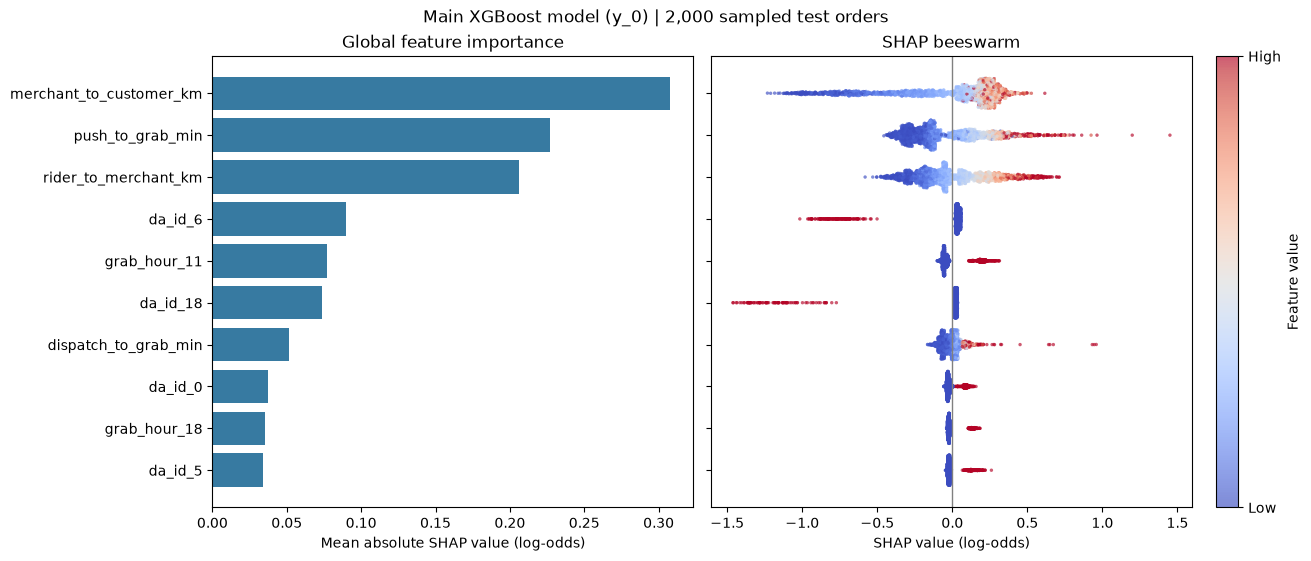

In [45]:
# 全局重要性按编码列统计；点颜色表示特征值高低。
top = importance.head(10)
names = top.index[::-1]
y_positions = np.arange(len(names))

fig, (bar_ax, swarm_ax) = plt.subplots(
    1, 2, figsize=(13, 5.5), sharey=True, layout="constrained",
)

bar_ax.barh(y_positions, top.loc[names], color="#377aa1")
bar_ax.set_yticks(y_positions, labels=names)
bar_ax.set(
    title="Global feature importance",
    xlabel="Mean absolute SHAP value (log-odds)",
)

swarm_ax.axvline(0, color="gray", linewidth=1)
swarm_rng = np.random.default_rng(RANDOM_SEED)

for row, name in enumerate(names):
    values = sample_phi[name].to_numpy()
    feature_values = sample_encoded[:, feature_names.index(name)]

    # 同贡献区间内交错排点，随机种子固定。
    bin_width = max(float(np.ptp(values)) / 50, 1e-12)
    buckets = np.floor((values - values.min()) / bin_width).astype(int)
    offsets = np.zeros(len(values))
    for bucket in np.unique(buckets):
        members = np.flatnonzero(buckets == bucket)
        swarm_rng.shuffle(members)
        slots = np.arange(len(members))
        offsets[members] = ((slots + 1) // 2) * np.where(slots % 2 == 0, -1, 1)
    offsets *= 0.36 / max(np.abs(offsets).max(), 1)

    # 连续特征按 P5–P95 映射颜色，仅影响显示。
    low, high = (
        np.quantile(feature_values, [0.05, 0.95])
        if name in numeric_features else (0, 1)
    )
    colors = np.clip((feature_values - low) / max(float(high - low), 1e-12), 0, 1)
    points = swarm_ax.scatter(
        values, row + offsets, c=colors, cmap="coolwarm",
        vmin=0, vmax=1, s=6, alpha=0.65, linewidths=0,
    )

swarm_ax.set(title="SHAP beeswarm", xlabel="SHAP value (log-odds)")
colorbar = fig.colorbar(points, ax=swarm_ax, ticks=[0, 1])
colorbar.ax.set_yticklabels(["Low", "High"])
colorbar.set_label("Feature value")
fig.suptitle("Main XGBoost model (y_0) | 2,000 sampled test orders")
plt.show()


在抽样的 2,000 笔测试订单中，商家至顾客距离的平均绝对 SHAP 值最高，为 0.3078；其次为推送至接单耗时和骑手至商家距离，分别为 0.2272 和 0.2062。较大的距离和较长的推送至接单耗时通常对应正向贡献，11 点接单的编码列也多呈正向贡献。

SHAP 值表示模型输出在 log-odds 尺度上的贡献，不是概率的百分点变化。排名按编码后的列计算，各小时和区域分别占一列。


In [46]:
# 案例取各结果组按分数排序后的中间订单，同分按 ID 排序。
threshold_10 = validation_thresholds.loc[
    validation_thresholds["method"].eq("XGBoost")
    & validation_thresholds["target_pct"].eq(10),
    "threshold",
].item()

alert = test_scores["xgboost_score"].ge(threshold_10)
late = test_scores["y_0"].eq(1)

case_masks = {
    "Hit (TP)": alert & late,
    "False alarm (FP)": alert & ~late,
    "Miss (FN)": ~alert & late,
}

case_rows = {}
for case, mask in case_masks.items():
    group = test_scores.loc[mask].sort_values(["xgboost_score", "order_id"])
    case_rows[case] = group.index[(len(group) - 1) // 2]

case_index = pd.Index(list(case_rows.values()))
case_phi, case_base, _ = explain_rows(case_index)

case_summary = test_scores.loc[case_index, ["y_0", "xgboost_score"]].copy()
case_summary["alert"] = alert.loc[case_index]
case_summary["log_odds"] = case_base + case_phi.sum(axis=1)

case_summary["distance_km"] = X_test.loc[case_index, "merchant_to_customer_km"]
case_summary["push_to_grab_min"] = X_test.loc[case_index, "push_to_grab_min"]
case_summary.index = list(case_rows)

display(case_summary.round(4))


,y_0,xgboost_score,alert,log_odds,distance_km,push_to_grab_min
Hit (TP),1,0.3005,True,-0.8448,1.8067,6.5500
False alarm (FP),0,0.2909,True,-0.8912,2.3891,9.3167
Miss (FN),1,0.1667,False,-1.6092,0.5048,9.7333


三个案例分别取自命中、误报和漏报组内按风险分数排序后的中间位置，仅用于解释个别预测。

| 案例 | 实际晚到 | 模型晚到分数 | 达到阈值 | 最终 log-odds |
|---|---:|---:|---|---:|
| 命中 | 是 | 30.05% | 是 | −0.8448 |
| 误报 | 否 | 29.09% | 是 | −0.8912 |
| 漏报 | 是 | 16.67% | 否 | −1.6092 |


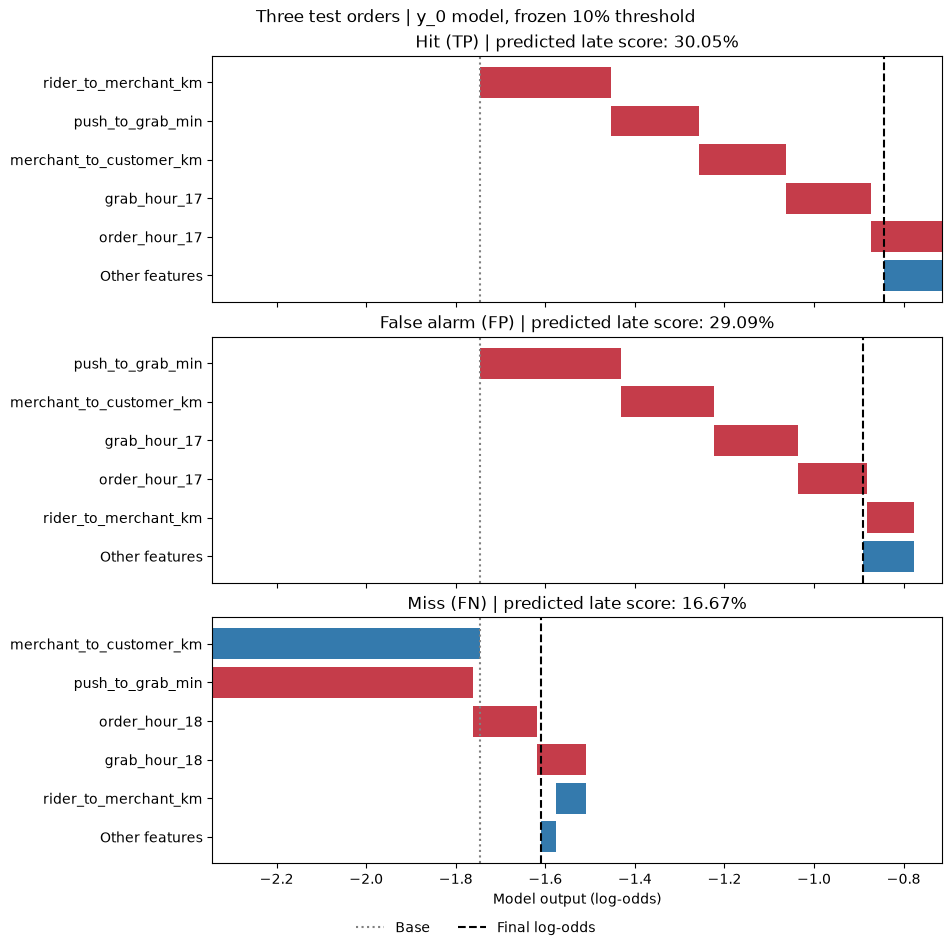

In [47]:
# 展示绝对贡献最大的五列，其余列合并；贡献单位为 log-odds。
fig, axes = plt.subplots(
    3, 1, figsize=(9.4, 9.4), sharex=True, layout="constrained",
)

for ax, (case, index) in zip(axes, case_rows.items()):
    phi = case_phi.loc[index]

    largest = phi.loc[phi.abs().nlargest(5).index]
    steps = pd.concat([
        largest,
        pd.Series({"Other features": phi.sum() - largest.sum()}),
    ])

    base = float(case_base.loc[index])
    ends = base + steps.cumsum()
    starts = ends - steps

    ax.barh(
        steps.index, steps, left=starts,
        color=np.where(steps.ge(0), "#c53c4a", "#347aad"),
    )
    ax.axvline(base, color="gray", linestyle=":", label="Base")
    ax.axvline(ends.iloc[-1], color="black", linestyle="--", label="Final log-odds")
    ax.invert_yaxis()

    score = test_scores.loc[index, "xgboost_score"]
    ax.set_title(f"{case} | predicted late score: {score:.2%}")

axes[-1].set_xlabel("Model output (log-odds)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle("Three test orders | y_0 model, frozen 10% threshold")
plt.show()


命中案例中，骑手接单位置距商家约 1.46 公里，对应 SHAP 贡献约 +0.293；推送至接单耗时及配送距离也提高模型分数。最终分数为 30.05%，超过固定阈值，订单实际晚到。

误报案例中，推送至接单耗时约 9.32 分钟，是最大的正向贡献，约 +0.314。模型分数为 29.09%，触发预警，但订单最终准时送达。

漏报案例中，约 9.73 分钟的推送至接单耗时贡献 +0.583，而约 0.50 公里的配送距离贡献 −0.597。两项贡献大致抵消，最终分数为 16.67%，低于阈值，订单实际晚到。


## 11. 分组误差分析

本节固定使用 `y_0` XGBoost 的 10% 验证目标阈值，按预约类型、接单时段、距离和测试日期汇总。FPR 的分母为组内实际准时订单，FNR 的分母为组内实际晚到订单；同时保留订单数及误报、漏报笔数。


In [48]:
# 使用主模型固定阈值，构造互斥的 TP、FP、FN、TN 标记。
error_rows = test_scores[
    ["order_id", "grab_date", "y_0", "xgboost_score"]
].copy()

alert = error_rows["xgboost_score"].ge(threshold_10)
late = error_rows["y_0"].eq(1)

error_rows["TP"] = (alert & late).astype(int)
error_rows["FP"] = (alert & ~late).astype(int)
error_rows["FN"] = (~alert & late).astype(int)
error_rows["TN"] = (~alert & ~late).astype(int)

error_rows["booking_type"] = df_test["is_prebook"].map({
    0: "On-demand",
    1: "Prebooked",
})

error_rows["accept_period"] = pd.cut(
    df_test["grab_time_dt"].dt.hour,
    bins=[0, 6, 10, 14, 17, 21, 24],
    labels=["00–06", "06–10", "10–14", "14–17", "17–21", "21–24"],
    right=False,
)

error_rows["distance_band"] = pd.cut(
    df_test["merchant_to_customer_km"],
    bins=[0, 1, 2, 3, 5, np.inf],
    labels=["[0, 1)", "[1, 2)", "[2, 3)", "[3, 5)", "[5, ∞)"],
    right=False,
)

error_rows["test_date"] = error_rows["grab_date"].dt.strftime("%m-%d")

count_cols = ["TP", "FP", "FN", "TN"]

assert error_rows[count_cols].sum(axis=1).eq(1).all()


In [49]:
# FPR 以实际准时数为分母，FNR 以实际晚到数为分母。
def add_error_rates(counts):
    table = counts.copy()

    table["on_time_n"] = table["FP"] + table["TN"]
    table["late_n"] = table["FN"] + table["TP"]
    table["orders"] = table["on_time_n"] + table["late_n"]

    table["alert_pct"] = 100 * (table["TP"] + table["FP"]) / table["orders"]

    # 分母为零时保留缺失，避免产生无意义的错误率。
    table["fpr_pct"] = 100 * table["FP"] / table["on_time_n"].replace(0, np.nan)
    table["fnr_pct"] = 100 * table["FN"] / table["late_n"].replace(0, np.nan)
    return table


overall_errors = add_error_rates(
    error_rows[count_cols].sum().to_frame().T
)
display(overall_errors.round(2))

breakdowns = {
    "Booking type": "booking_type",
    "Acceptance period": "accept_period",
    "Distance (km)": "distance_band",
    "Test date": "test_date",
}

group_tables = {}
show_cols = ["orders", "on_time_n", "late_n", "FP", "FN", "alert_pct", "fpr_pct", "fnr_pct"]

for title, col in breakdowns.items():
    grouped_counts = (
        error_rows.groupby(col, observed=True, dropna=False)[count_cols]
        .sum()
    )
    group_tables[title] = add_error_rates(grouped_counts)

    print(title)
    display(group_tables[title][show_cols].round(2))


,TP,FP,FN,TN,on_time_n,late_n,orders,alert_pct,fpr_pct,fnr_pct
0,4537,10580,17385,112566,123146,21922,145068,10.42,8.59,79.3


Booking type


,orders,on_time_n,late_n,FP,FN,alert_pct,fpr_pct,fnr_pct
booking_type,,,,,,,,
On-demand,139779,118945,20834,9758,16642,9.98,8.20,79.88
Prebooked,5289,4201,1088,822,743,22.06,19.57,68.29


Acceptance period


,orders,on_time_n,late_n,FP,FN,alert_pct,fpr_pct,fnr_pct
accept_period,,,,,,,,
00–06,3597,3166,431,131,354,5.78,4.14,82.13
06–10,8338,7315,1023,153,925,3.01,2.09,90.42
10–14,56744,48382,8362,3545,7059,8.54,7.33,84.42
14–17,17167,14878,2289,319,2095,2.99,2.14,91.52
17–21,48860,40466,8394,6119,5693,18.05,15.12,67.82
21–24,10362,8939,1423,313,1259,4.60,3.50,88.48


Distance (km)


,orders,on_time_n,late_n,FP,FN,alert_pct,fpr_pct,fnr_pct
distance_band,,,,,,,,
"[0, 1)",43856,39984,3872,707,3519,2.42,1.77,90.88
"[1, 2)",57281,48189,9092,4177,7384,10.27,8.67,81.21
"[2, 3)",33221,26607,6614,4179,4909,17.71,15.71,74.22
"[3, 5)",9213,7220,1993,1348,1337,21.75,18.67,67.08
"[5, ∞)",1497,1146,351,169,236,18.97,14.75,67.24


Test date


,orders,on_time_n,late_n,FP,FN,alert_pct,fpr_pct,fnr_pct
test_date,,,,,,,,
10-23,77719,64811,12908,5699,10223,10.79,8.79,79.20
10-24,67349,58335,9014,4881,7162,10.00,8.37,79.45


| 结果 | 笔数 |
|---|---:|
| 命中 TP | 4,537 |
| 误报 FP | 10,580 |
| 漏报 FN | 17,385 |
| 正确放行 TN | 112,566 |
| 合计 | 145,068 |

总体误报率 FPR = 10,580 / 123,146 = 8.59%，分母为实际准时订单；漏报率 FNR = 17,385 / 21,922 = 79.30%，分母为实际晚到订单。FPR 与预警中的误报比例不同；FNR 等于 1 减去覆盖率。在当前监控容量下，大部分晚到订单仍未被识别。


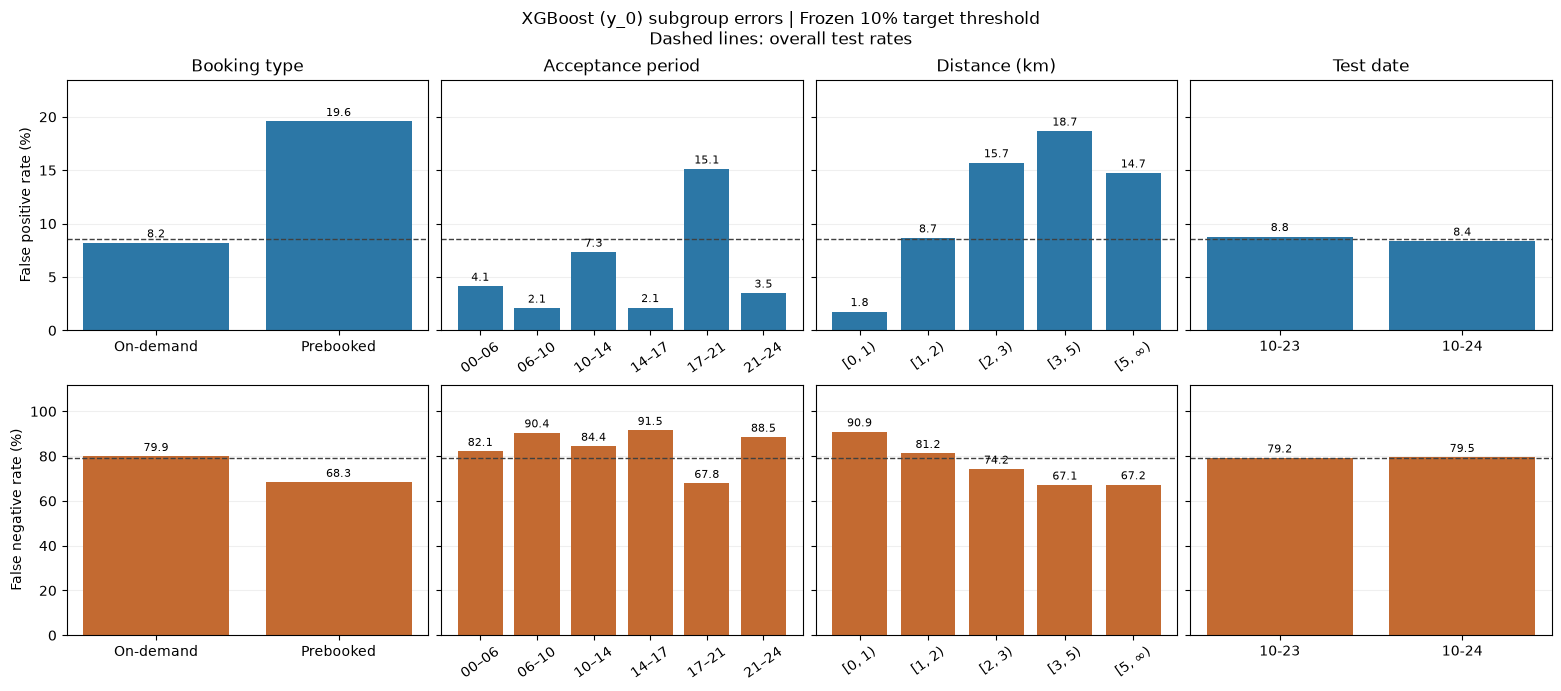

In [50]:
fig, axes = plt.subplots(
    2, 4, figsize=(15.5, 6.8), sharey="row", layout="constrained",
)

for j, (title, table) in enumerate(group_tables.items()):
    labels = table.index.astype(str).tolist()
    positions = np.arange(len(labels))

    for i, (metric, color) in enumerate([
        ("fpr_pct", "#2c77a6"),
        ("fnr_pct", "#c36a31"),
    ]):
        ax = axes[i, j]
        bars = ax.bar(positions, table[metric], color=color)

        ax.axhline(
            overall_errors[metric].iloc[0],
            color="#404040", linestyle="--", linewidth=1,
        )
        ax.set_xticks(positions, labels, rotation=35 if j in (1, 2) else 0)
        ax.bar_label(bars, fmt="%.1f", padding=2, fontsize=8)
        ax.grid(axis="y", alpha=0.2)
        ax.set_axisbelow(True)

        if i == 0:
            ax.set_title(title)

axes[0, 0].set_ylabel("False positive rate (%)")
axes[1, 0].set_ylabel("False negative rate (%)")

max_fpr = max(table["fpr_pct"].max() for table in group_tables.values())
axes[0, 0].set_ylim(0, 1.20 * max_fpr)
axes[1, 0].set_ylim(0, 112)

fig.suptitle(
    "XGBoost (y_0) subgroup errors | Frozen 10% target threshold\n"
    "Dashed lines: overall test rates"
)
plt.show()


预约订单的 FPR 为 19.57%，高于非预约订单的 8.20%；其 FNR 为 68.29%，低于非预约订单的 79.88%。两组实际监控率分别为 22.06% 和 9.98%。这些差异同时反映了预警负担与漏报水平。

17:00–20:59 的 FPR 最高，为 15.12%，包含 6,119 笔误报，占全部误报的 57.84%。14:00–16:59 的 FNR 最高，为 91.52%；10:00–13:59 的漏报笔数最多，为 7,059 笔。组内错误率与错误总量回答不同问题。

距离不足 1 公里的订单 FNR 为 90.88%。[1, 2) 公里组的 FNR 为 81.21%，低于不足 1 公里组，但高于 2 公里以上各组。其订单基数为 57,281 笔，包含 9,092 笔实际晚到，最终漏报 7,384 笔。该组漏报最多，不能据此认定其组内识别表现最差。10 月 23 日和 24 日的 FNR 分别为 79.20% 和 79.45%，仅表明这两天的漏报比例接近。

### 运营含义（Operational implications）

预约组较高的 FPR 提示需要检查其风险分数分布及记录 ETA 特征；现有分组结果不能确定误报成因。17–21 点的误报量较大，可作为评估高峰预警处理负担的依据。14–17 点的高 FNR 表明统一阈值在该时段漏掉了较大比例的晚到订单，应优先复核漏报样本。[1, 2) 公里组则需要结合订单基数评估总漏报负担。



## 12. 接单时的 ETA 提前量

定义 `lead_min = (estimate_arrived_time - grab_time) / 60`，相对于数据中记录的 ETA 计算。提前量大于 0 表示接单时尚未到 ETA；小于或等于 0 的命中不属于 ETA 前预警。分位数与至少 5、10、15 分钟的比例仅在正提前量子集中计算。


In [51]:
# 提前量相对于记录 ETA 计算，仅用于回溯评估。
lead_rows = error_rows[["order_id", "TP", "FP"]].copy()

time_cols = ["estimate_arrived_time", "grab_time"]
lead_rows[time_cols] = df_test.loc[lead_rows.index, time_cols]

lead_rows["lead_min"] = (
    lead_rows["estimate_arrived_time"] - lead_rows["grab_time"]
) / 60

all_alerts = lead_rows["TP"].eq(1) | lead_rows["FP"].eq(1)
hit_alerts = lead_rows["TP"].eq(1)

remaining_by_group = {
    "All test orders": lead_rows["lead_min"],
    "All alerts": lead_rows.loc[all_alerts, "lead_min"],
    "Hit alerts": lead_rows.loc[hit_alerts, "lead_min"],
}

# 已到或超过 ETA 的订单单列，不计为 ETA 前预警。
at_or_past_eta_orders = lead_rows.loc[lead_rows["lead_min"].le(0)].copy()

eta_rows = []
for group, remaining in remaining_by_group.items():
    at_or_past_eta = remaining.le(0)
    eta_rows.append({
        "group": group,
        "total": len(remaining),
        "positive_lead": remaining.gt(0).sum(),
        "exactly_eta": remaining.eq(0).sum(),
        "past_eta": remaining.lt(0).sum(),
        "at_or_past_eta": at_or_past_eta.sum(),
        "at_or_past_pct": 100 * at_or_past_eta.mean(),
    })

eta_status = pd.DataFrame(eta_rows).set_index("group")
display(eta_status.round(2))


,total,positive_lead,exactly_eta,past_eta,at_or_past_eta,at_or_past_pct
group,,,,,,
All test orders,145068,144924,1,143,144,0.10
All alerts,15117,15041,1,75,76,0.50
Hit alerts,4537,4461,1,75,76,1.68


In [52]:
# 分位数与时间窗口比例仅使用正提前量订单。
positive_groups = {}
for group in ["All alerts", "Hit alerts"]:
    remaining = remaining_by_group[group]
    positive_groups[group] = remaining.loc[remaining.gt(0)]

quantile_levels = {"P10": 0.10, "P25": 0.25, "P50": 0.50,
                   "P75": 0.75, "P90": 0.90}
minutes = [5, 10, 15]
quantile_rows = []
window_rows = []

for group, remaining in positive_groups.items():
    quantile_row = {"group": group, "positive_lead_n": len(remaining)}
    for name, level in quantile_levels.items():
        quantile_row[name] = remaining.quantile(level)
    quantile_rows.append(quantile_row)

    for cutoff in minutes:
        # 使用未取整分钟数，时间门槛包含等号。
        count = remaining.ge(cutoff).sum()
        window_rows.append({
            "group": group,
            "min_required": cutoff,
            "positive_lead_n": len(remaining),
            "n_at_least": count,
            "pct_at_least": 100 * count / len(remaining),
        })

lead_quantiles = pd.DataFrame(quantile_rows).set_index("group")
lead_windows = pd.DataFrame(window_rows)

display(lead_quantiles.round(2))
display(lead_windows.round(2))


,positive_lead_n,P10,P25,P50,P75,P90
group,,,,,,
All alerts,15041,26.07,31.20,37.7,44.10,49.90
Hit alerts,4461,20.92,28.42,35.3,42.03,47.47


,group,min_required,positive_lead_n,n_at_least,pct_at_least
0,All alerts,5,15041,15009,99.79
1,All alerts,10,15041,14930,99.26
2,All alerts,15,15041,14784,98.29
3,Hit alerts,5,4461,4429,99.28
4,Hit alerts,10,4461,4352,97.56
5,Hit alerts,15,4461,4237,94.98


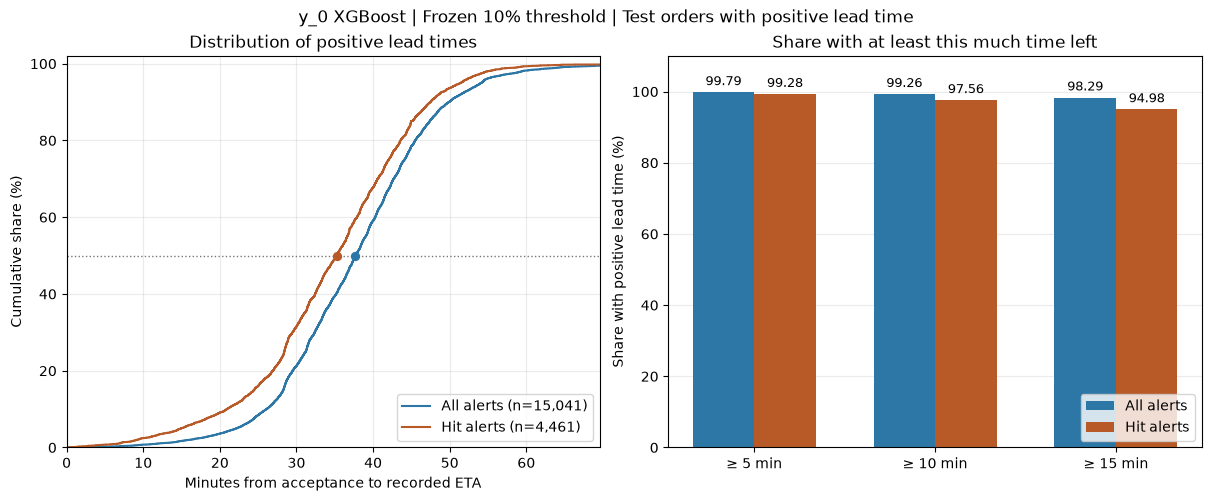

In [53]:
# 经验累计分布使用全部正提前量订单，纵轴为组内累计比例。
fig, (cdf_ax, window_ax) = plt.subplots(
    1, 2, figsize=(12, 4.9), layout="constrained",
)
colors = {"All alerts": "#2c77a6", "Hit alerts": "#b85a28"}

for group, remaining in positive_groups.items():
    sorted_minutes = remaining.sort_values().to_numpy()
    x = np.r_[0, sorted_minutes]
    y = 100 * np.arange(len(x)) / len(sorted_minutes)
    cdf_ax.step(
        x, y, where="post", color=colors[group],
        label=f"{group} (n={len(remaining):,})",
    )

    median = lead_quantiles.loc[group, "P50"]
    cdf_ax.scatter(median, 50, color=colors[group], s=32, zorder=3)

cdf_ax.axhline(50, color="#777777", linestyle=":", linewidth=1)

# P99.5 仅限制显示范围，不排除统计样本。
right_edge = max(remaining.quantile(0.995) for remaining in positive_groups.values())
cdf_ax.set(
    xlim=(0, right_edge), ylim=(0, 102),
    xlabel="Minutes from acceptance to recorded ETA",
    ylabel="Cumulative share (%)",
    title="Distribution of positive lead times",
)
cdf_ax.legend(loc="lower right")
cdf_ax.grid(alpha=0.25)

# 柱形图比例以各组正提前量订单数为分母。
positions = np.arange(len(minutes))
width = 0.34

for j, group in enumerate(positive_groups):
    percentages = lead_windows.loc[
        lead_windows["group"].eq(group), "pct_at_least"
    ]
    bars = window_ax.bar(
        positions + (j - 0.5) * width,
        percentages, width, color=colors[group], label=group,
    )
    window_ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)

window_ax.set_xticks(positions, [f"≥ {cutoff} min" for cutoff in minutes])
window_ax.set(
    ylim=(0, 110),
    ylabel="Share with positive lead time (%)",
    title="Share with at least this much time left",
)
window_ax.legend(loc="lower right")
window_ax.grid(axis="y", alpha=0.25)
window_ax.set_axisbelow(True)

fig.suptitle("y_0 XGBoost | Frozen 10% threshold | Test orders with positive lead time")
plt.show()


在 4,537 笔命中订单中，**4,461 笔在接单时仍有正 ETA 提前量**，占全部命中的 98.32%；**76 笔已到或超过记录 ETA**，其中 1 笔恰好到达 ETA、75 笔已超过 ETA，不能计为 ETA 前预警。

正提前量命中的中位提前量为 35.30 分钟；全部正提前量预警的中位数为 37.70 分钟。命中订单中有 **4,237 笔至少提前 15 分钟**，占正提前量命中的 94.98%，占全部命中的 93.39%。右图的比例以各组正提前量订单为分母，未包含已到或超过 ETA 的订单。



## 13. 概率预测诊断

使用 Brier 分数和等宽分箱曲线检验原始 XGBoost 分数。常数基准为训练集 `y_0` 正例率，验证、测试阶段使用同一常数。分箱曲线同时报告各箱订单数，以区分校准偏差与小样本波动。


In [54]:
# 常数概率基准仅使用训练集晚到率，验证与测试复用该值。
from sklearn.metrics import brier_score_loss

score_sets = {
    "Validation": validation_scores,
    "Test": test_scores,
}

train_late_rate = y_train["y_0"].mean()
brier_rows = []

for split, scores in score_sets.items():
    y_true = scores["y_0"]
    p = scores["xgboost_score"]

    p_base = np.full(len(scores), train_late_rate)

    brier_rows.append({
        "split": split,
        "orders": len(scores),
        "mean_score_pct": 100 * p.mean(),
        "actual_late_pct": 100 * y_true.mean(),
        "xgboost_brier": brier_score_loss(y_true, p),
        "constant_brier": brier_score_loss(y_true, p_base),
    })

brier_summary = pd.DataFrame(brier_rows).set_index("split")
print(f"常数基准使用的训练集晚到率为 {train_late_rate:.2%}")
display(brier_summary.round(5))


常数基准使用的训练集晚到率为 14.92%


,orders,mean_score_pct,actual_late_pct,xgboost_brier,constant_brier
split,,,,,
Validation,77230,14.86733,15.09258,0.12092,0.12815
Test,145068,14.99853,15.11153,0.12137,0.12828


In [55]:
# 分箱右闭，首箱包含零；各箱同时报告样本量与校准偏差。
bin_edges = np.linspace(0, 1, 11)
bin_labels = [f"{lo}–{lo + 10}%" for lo in range(0, 100, 10)]
calibration_tables = {}

for split, scores in score_sets.items():
    binned = scores.assign(score_bin=pd.cut(
        scores["xgboost_score"],
        bins=bin_edges,
        labels=bin_labels,
        include_lowest=True,
    ))

    table = binned.groupby("score_bin", observed=True).agg(
        orders=("y_0", "size"),
        mean_score=("xgboost_score", "mean"),
        late_rate=("y_0", "mean"),
    )

    # 差值为实际晚到率减平均分数，单位为百分点。
    table["gap_pp"] = 100 * (table["late_rate"] - table["mean_score"])
    calibration_tables[split] = table

    print(split)
    display(table.assign(
        mean_score_pct=100 * table["mean_score"].astype(float),
        actual_late_pct=100 * table["late_rate"],
    )[["orders", "mean_score_pct", "actual_late_pct", "gap_pp"]].round(2))


Validation


,orders,mean_score_pct,actual_late_pct,gap_pp
score_bin,,,,
0–10%,23540,5.59,5.79,0.20
10–20%,34288,14.97,15.42,0.44
20–30%,16021,23.89,23.49,-0.40
30–40%,2929,33.26,33.63,0.37
40–50%,268,43.30,49.25,5.95
50–60%,88,54.13,56.82,2.69
60–70%,45,64.25,73.33,9.08
70–80%,45,74.12,82.22,8.10
80–90%,6,82.00,100.00,18.00


Test


,orders,mean_score_pct,actual_late_pct,gap_pp
score_bin,,,,
0–10%,43829,5.62,5.90,0.28
10–20%,64138,14.99,15.37,0.39
20–30%,30554,23.95,23.49,-0.46
30–40%,5562,33.30,31.25,-2.05
40–50%,585,43.75,47.52,3.77
50–60%,156,54.14,62.18,8.04
60–70%,108,65.11,59.26,-5.85
70–80%,118,74.51,86.44,11.93
80–90%,18,81.94,94.44,12.50


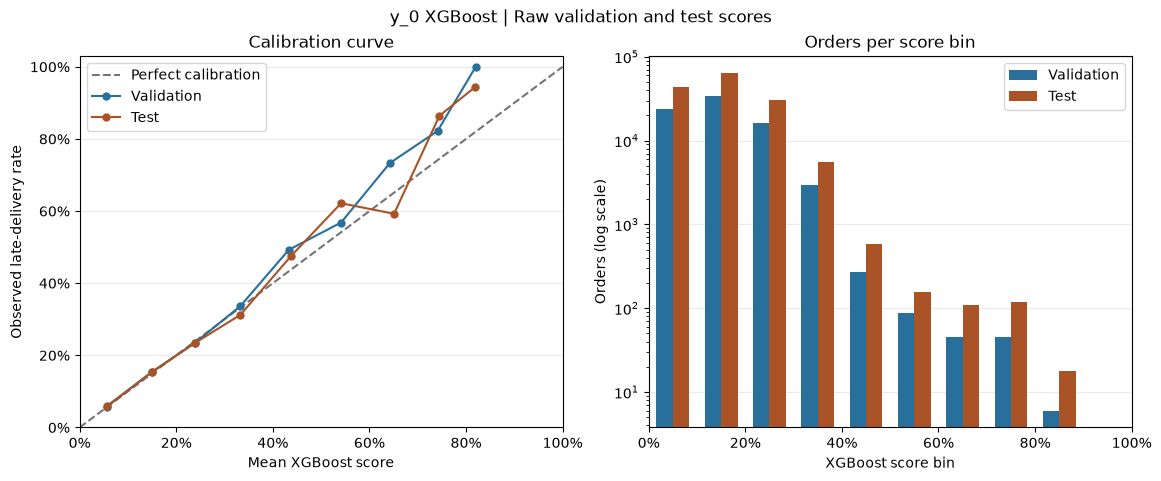

In [56]:
# 校准曲线按非空分箱绘制；样本量采用对数轴并跳过空箱。
from matplotlib.ticker import PercentFormatter

fig, (cal_ax, count_ax) = plt.subplots(
    1, 2, figsize=(11.5, 4.7), layout="constrained",
)

cal_ax.plot([0, 1], [0, 1], "--", color="#747474", label="Perfect calibration")

centers = (bin_edges[:-1] + bin_edges[1:]) / 2
width = 0.034
colors = {"Validation": "#296f9c", "Test": "#a95327"}

for j, (split, table) in enumerate(calibration_tables.items()):
    cal_ax.plot(
        table["mean_score"], table["late_rate"],
        marker="o", markersize=5, color=colors[split], label=split,
    )

    counts = table["orders"].reindex(bin_labels, fill_value=0).to_numpy()
    has_orders = counts > 0
    count_ax.bar(
        centers[has_orders] + (j - 0.5) * width,
        counts[has_orders],
        width=width, color=colors[split], label=split,
    )

cal_ax.set(
    xlim=(0, 1), ylim=(0, 1.03),
    xlabel="Mean XGBoost score", ylabel="Observed late-delivery rate",
    title="Calibration curve",
)
cal_ax.yaxis.set_major_formatter(PercentFormatter(1))
cal_ax.legend(loc="upper left")

count_ax.set(
    xlim=(0, 1), yscale="log",
    xlabel="XGBoost score bin", ylabel="Orders (log scale)",
    title="Orders per score bin",
)
count_ax.legend(loc="upper right")

for ax in (cal_ax, count_ax):
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("y_0 XGBoost | Raw validation and test scores")
plt.show()


测试集 XGBoost 的 Brier 分数为 0.12137，低于以训练集晚到率作为常数预测的 0.12828；验证集对应值为 0.12092 和 0.12815。Brier 分数越低表示概率预测的均方误差越小，但单一分数不能证明所有风险区间均已校准。

测试集 30%–40% 分数档的平均预测为 33.30%，实际晚到率为 31.25%，高估约 2.05 个百分点。99.32% 的测试订单分数不超过 40%，较高分数档样本较少，分箱晚到率的波动需结合订单数解读。


## 14. 结果导出与一致性检查

导出测试订单的风险分数、预警标记、事后结果、业务分组和记录 ETA 提前量，并生成整体与逐日指标。CSV 保留完整分数和阈值精度；读回后检查订单唯一性、逐单阈值判断，以及命中数和 Brier 分数与前文一致。订单级文件中的真实标签和结果属于事后评估信息。


In [57]:
# 保留逐单风险分数的完整精度，避免改变阈值附近的预警判断。
dashboard_orders = (
    test_scores[["order_id", "grab_date", "xgboost_score", "y_0"]]
    .rename(columns={"xgboost_score": "risk_score"})
    .copy()
)

dashboard_orders["order_id"] = dashboard_orders["order_id"].astype("string")
dashboard_orders["grab_date"] = dashboard_orders["grab_date"].dt.strftime("%Y-%m-%d")

dashboard_orders["risk_score"] = dashboard_orders["risk_score"].astype(float)

alerted = dashboard_orders["risk_score"].ge(threshold_10)
actual_late = dashboard_orders["y_0"].eq(1)
dashboard_orders["alert"] = alerted.astype("int8")

dashboard_orders["outcome"] = np.select(
    [alerted & actual_late, alerted & ~actual_late, ~alerted & actual_late],
    ["TP", "FP", "FN"],
    default="TN",
)

# 在排序前按原始索引对齐分组和提前量。
filter_cols = ["booking_type", "accept_period", "distance_band"]
dashboard_orders[filter_cols] = error_rows.loc[dashboard_orders.index, filter_cols]
dashboard_orders["lead_min"] = lead_rows.loc[dashboard_orders.index, "lead_min"]

# 同分按 ID 排序，固定导出顺序。
dashboard_orders = dashboard_orders.sort_values(
    ["risk_score", "order_id"], ascending=[False, True], ignore_index=True,
)

print(f"测试订单数 {len(dashboard_orders):,}")
print(f"预警笔数 {dashboard_orders['alert'].sum():,}")
display(dashboard_orders.head())


测试订单数 145,068
预警笔数 15,117


,order_id,grab_date,risk_score,y_0,alert,outcome,booking_type,accept_period,distance_band,lead_min
0,200265,2022-10-23,0.865365,1,1,TP,On-demand,17–21,"[2, 3)",-25.550000
1,212568,2022-10-24,0.840168,1,1,TP,On-demand,17–21,"[0, 1)",9.866667
2,15510,2022-10-23,0.832486,1,1,TP,On-demand,17–21,"[2, 3)",-4.783333
3,37999,2022-10-23,0.832061,1,1,TP,On-demand,17–21,"[1, 2)",-10.750000
4,241535,2022-10-24,0.825334,1,1,TP,On-demand,10–14,"[1, 2)",11.083333


In [58]:
# 整体与逐日指标分别重算，保持各项比例的分母一致。
def summarize_dashboard(orders, scope):
    counts = orders["outcome"].value_counts()
    tp, fp, fn, tn = (
        int(counts.get(code, 0)) for code in ["TP", "FP", "FN", "TN"]
    )
    n = len(orders)
    alerts = tp + fp
    late_orders = tp + fn

    y_true = orders["y_0"]
    risk_score = orders["risk_score"]

    # 已到或超过 ETA 的命中单列；中位数仅用正提前量命中。
    hit_lead = orders.loc[orders["outcome"].eq("TP"), "lead_min"]
    positive_hit_lead = hit_lead[hit_lead.gt(0)]

    return {
        "scope": scope,
        "start_date": orders["grab_date"].min(),
        "end_date": orders["grab_date"].max(),
        "model": "XGBoost",
        "target": "y_0",
        "target_alert_pct": 10,
        "threshold": threshold_10,
        "orders": n,
        "late_orders": late_orders,
        "late_pct": 100 * late_orders / n,
        "alerts": alerts,
        "tp": tp, "fp": fp, "fn": fn, "tn": tn,

        # 百分比均以 0–100 存储；精确率与覆盖率分母不同。
        "actual_alert_pct": 100 * alerts / n,
        "precision_pct": 100 * tp / alerts if alerts else np.nan,
        "coverage_pct": 100 * tp / late_orders if late_orders else np.nan,
        "fpr_pct": 100 * fp / (fp + tn) if fp + tn else np.nan,
        "fnr_pct": 100 * fn / late_orders if late_orders else np.nan,

        "ap": average_precision_score(y_true, risk_score),
        "roc_auc": roc_auc_score(y_true, risk_score),
        "brier": brier_score_loss(y_true, risk_score),
        "hits_at_or_past_eta": int(hit_lead.le(0).sum()),
        "positive_lead_hits": len(positive_hit_lead),
        "median_positive_hit_lead_min": positive_hit_lead.median(),
        "hits_at_least_15min": int(positive_hit_lead.ge(15).sum()),
    }


summary_rows = [summarize_dashboard(dashboard_orders, "overall")]
for _, day_orders in dashboard_orders.groupby("grab_date", sort=True):
    summary_rows.append(summarize_dashboard(day_orders, "daily"))

dashboard_metrics = pd.DataFrame(summary_rows)

display(dashboard_metrics[[
    "scope", "start_date", "end_date", "orders", "late_orders",
    "alerts", "tp", "actual_alert_pct", "precision_pct", "coverage_pct",
]].round(2))


,scope,start_date,end_date,orders,late_orders,alerts,tp,actual_alert_pct,precision_pct,coverage_pct
0,overall,2022-10-23,2022-10-24,145068,21922,15117,4537,10.42,30.01,20.70
1,daily,2022-10-23,2022-10-23,77719,12908,8384,2685,10.79,32.03,20.80
2,daily,2022-10-24,2022-10-24,67349,9014,6733,1852,10.00,27.51,20.55


In [59]:
# 创建结果目录并导出；读回后核对标识、阈值判断及汇总指标。
output_dir = Path("../results").resolve()
output_dir.mkdir(parents=True, exist_ok=True)

order_path = output_dir / "dashboard_order_scores.csv"
metric_path = output_dir / "dashboard_metrics.csv"

dashboard_orders.to_csv(order_path, index=False, encoding="utf-8")
dashboard_metrics.to_csv(metric_path, index=False, encoding="utf-8")

# ID 按文本读入，浮点数按完整精度往返。
orders_read = pd.read_csv(
    order_path, dtype={"order_id": "string"}, float_precision="round_trip",
)
metrics_read = pd.read_csv(metric_path, float_precision="round_trip")

overall = metrics_read.loc[metrics_read["scope"].eq("overall")].iloc[0]
previous = test_fixed.loc[
    test_fixed["method"].eq("XGBoost") & test_fixed["target_pct"].eq(10)
].iloc[0]

assert len(orders_read) == overall["orders"]
assert orders_read["order_id"].is_unique
assert orders_read["order_id"].equals(dashboard_orders["order_id"])

# 用读回分数逐单验证预警，避免导出舍入改变分类。
assert overall["threshold"] == threshold_10
assert orders_read["alert"].eq(
    orders_read["risk_score"].ge(overall["threshold"])
).all()

assert orders_read["alert"].sum() == overall["alerts"] == previous["monitored"]
assert orders_read["outcome"].eq("TP").sum() == overall["tp"] == previous["hits"]
assert np.isclose(overall["brier"], brier_summary.loc["Test", "xgboost_brier"])

print(f"订单明细 {len(orders_read):,} 行，指标汇总 {len(metrics_read)} 行")
print(f"读回阈值 {overall['threshold']:.10f}")
print(f"核对通过，共 {int(overall['alerts']):,} 笔预警，"
      f"其中 {int(overall['tp']):,} 笔命中")
print(order_path)
print(metric_path)


订单明细 145,068 行，指标汇总 3 行
读回阈值 0.2566608489
核对通过，共 15,117 笔预警，其中 4,537 笔命中
/Users/chronus/code/ai-bigdata-project/results/dashboard_order_scores.csv
/Users/chronus/code/ai-bigdata-project/results/dashboard_metrics.csv


## 15. 结果与局限

在 2022 年 10 月 23–24 日测试期，XGBoost 在 10% 验证目标对应的固定阈值下监控 10.42% 的订单，识别 20.70% 的 `y_0` 晚到订单，预警精确率为 30.01%。4,537 笔命中中，4,461 笔相对于记录 ETA 仍有正提前量，其中 4,237 笔至少提前 15 分钟。这支持将模型作为有限监控资源下的风险排序候选工具；是否减少晚到仍需干预实验检验。

评估仅覆盖 10 月 17–24 日这一连续短期窗口。时间顺序切分模拟了前瞻预测，并约束训练、验证标签的可得时间，但尚不能证明跨月份、节假日或不同运营条件的泛化能力。标签截止规则排除了部分跨日未完成订单，结论也仅适用于已接单且具有有效时间记录的样本。

记录 ETA 的历史版本、字段的在线读取时延及极端正耗时的业务有效性仍未确认。坐标经过匿名化处理，距离为近似地理距离。分组误差和 SHAP 分析均不识别因果效应；两天的测试结果也不足以判断长期运营收益。
